In [22]:
from google.colab import drive
drive.mount('/content/drive')

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from pathlib import Path
import shutil
from ultralytics import YOLO
import random

from collections import defaultdict
from IPython.display import display, Image
from ultralytics.utils.plotting import Annotator

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:

%pip install -q ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 74.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 9.7 MB/s eta 0:00:00


In [6]:
# Locate model and validation dataset
DRIVE_ROOT = Path("/content/drive/MyDrive/CrackVision")

WEIGHTS_PATH = (
    DRIVE_ROOT / "models" / "crackvision-yolo11n-seg-best.pt"
)

DATASET_DIR = Path("/content/crack-seg")
VAL_IMAGES_DIR = DATASET_DIR / "images" / "val"
VAL_LABELS_DIR = DATASET_DIR / "labels" / "val"

print("Model weights found:", WEIGHTS_PATH.exists())
print("Validation images found:", VAL_IMAGES_DIR.exists())
print("Validation labels found:", VAL_LABELS_DIR.exists())

Model weights found: True
Validation images found: False
Validation labels found: False


In [7]:
# Restore the dataset from google drive

DRIVE_ROOT = Path('/content/drive/MyDrive/CrackVision')

print("Searching for the dataset in Google Drive. \n")

for path in DRIVE_ROOT.rglob("crack-seg.yaml"):
  print("Found configuration:", path)
  print("Dataset folder:", path.parent)

Searching for the dataset in Google Drive. 

Found configuration: /content/drive/MyDrive/CrackVision/data/crack-seg/crack-seg.yaml
Dataset folder: /content/drive/MyDrive/CrackVision/data/crack-seg


In [9]:
# Restore the Dataset
DRIVE_DATASET_DIR = Path("/content/drive/MyDrive/CrackVision/data/crack-seg")
DATASET_DIR = Path("/content/crack-seg")

if not (DRIVE_DATASET_DIR / "crack-seg.yaml").exists():
    raise FileNotFoundError(
        f"Dataset configuration not found in {DRIVE_DATASET_DIR}"
    )

if DATASET_DIR.exists():
    shutil.rmtree(DATASET_DIR)

shutil.copytree(DRIVE_DATASET_DIR, DATASET_DIR)

VAL_IMAGES_DIR = DATASET_DIR / "images" / "val"
VAL_LABELS_DIR = DATASET_DIR / "labels" / "val"

print("Dataset restored successfully!")
print("Validation images directory exists:", VAL_IMAGES_DIR.exists())
print("Validation labels directory exists:", VAL_LABELS_DIR.exists())
print("Validation images:", len(list(VAL_IMAGES_DIR.glob("*"))) if VAL_IMAGES_DIR.exists() else 0)
print("Validation labels:", len(list(VAL_LABELS_DIR.glob("*"))) if VAL_LABELS_DIR.exists() else 0)

Dataset restored successfully!
Validation images directory exists: True
Validation labels directory exists: True
Validation images: 200
Validation labels: 200


In [10]:
DRIVE_ROOT = Path("/content/drive/MyDrive/CrackVision")
WEIGHTS_PATH = DRIVE_ROOT / "models" / "crackvision-yolo11n-seg-best.pt"

if not WEIGHTS_PATH.exists():
    raise FileNotFoundError(f"Model weights not found: {WEIGHTS_PATH}")

model = YOLO(str(WEIGHTS_PATH))

print("CrackVision model loaded successfully!")
print("Model:", WEIGHTS_PATH.name)
print("Task:", model.task)
print("Number of classes:", len(model.names))
print("Class names:", model.names)

CrackVision model loaded successfully!
Model: crackvision-yolo11n-seg-best.pt
Task: segment
Number of classes: 1
Class names: {0: 'crack'}


In [11]:
# Evaluate the Model
# Evaluate segmentation performance on the validation set.
# This does not train or modify the model.

VAL_DATA_YAML = DATASET_DIR / "crack-seg.yaml"

if not VAL_DATA_YAML.exists():
    raise FileNotFoundError(f"Dataset YAML not found: {VAL_DATA_YAML}")

metrics = model.val(
    data=str(VAL_DATA_YAML),
    split="val",
    imgsz=640,
    batch=8,
    plots=True,
    project="/content/drive/MyDrive/CrackVision/evaluation-results",
    name="validation-evaluation",
    exist_ok=True,
    verbose=True,
)

print("\n--- CrackVision Validation Results ---")
print(f"Box mAP50:       {metrics.box.map50:.4f}")
print(f"Box mAP50-95:    {metrics.box.map:.4f}")
print(f"Mask mAP50:      {metrics.seg.map50:.4f}")
print(f"Mask mAP50-95:   {metrics.seg.map:.4f}")

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,849,467 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 485.5±210.0 MB/s, size: 25.2 KB)
val: Scanning /content/crack-seg/labels/val... 200 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 967.7it/s 0.2s
val: New cache created: /content/crack-seg/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 3.6it/s 7.0s
                   all        200        249      0.835      0.731      0.788      0.596      0.729      0.639      0.635      0.215
Speed: 4.2ms preprocess, 9.6ms inference, 0.0ms loss, 4.9ms postprocess per image
Results saved to /content/drive/MyDrive/CrackVision/evaluation-results/validation-evaluation

--- CrackVision Validation Results ---
Box mAP50:       0.7883
Box mAP50-95:    

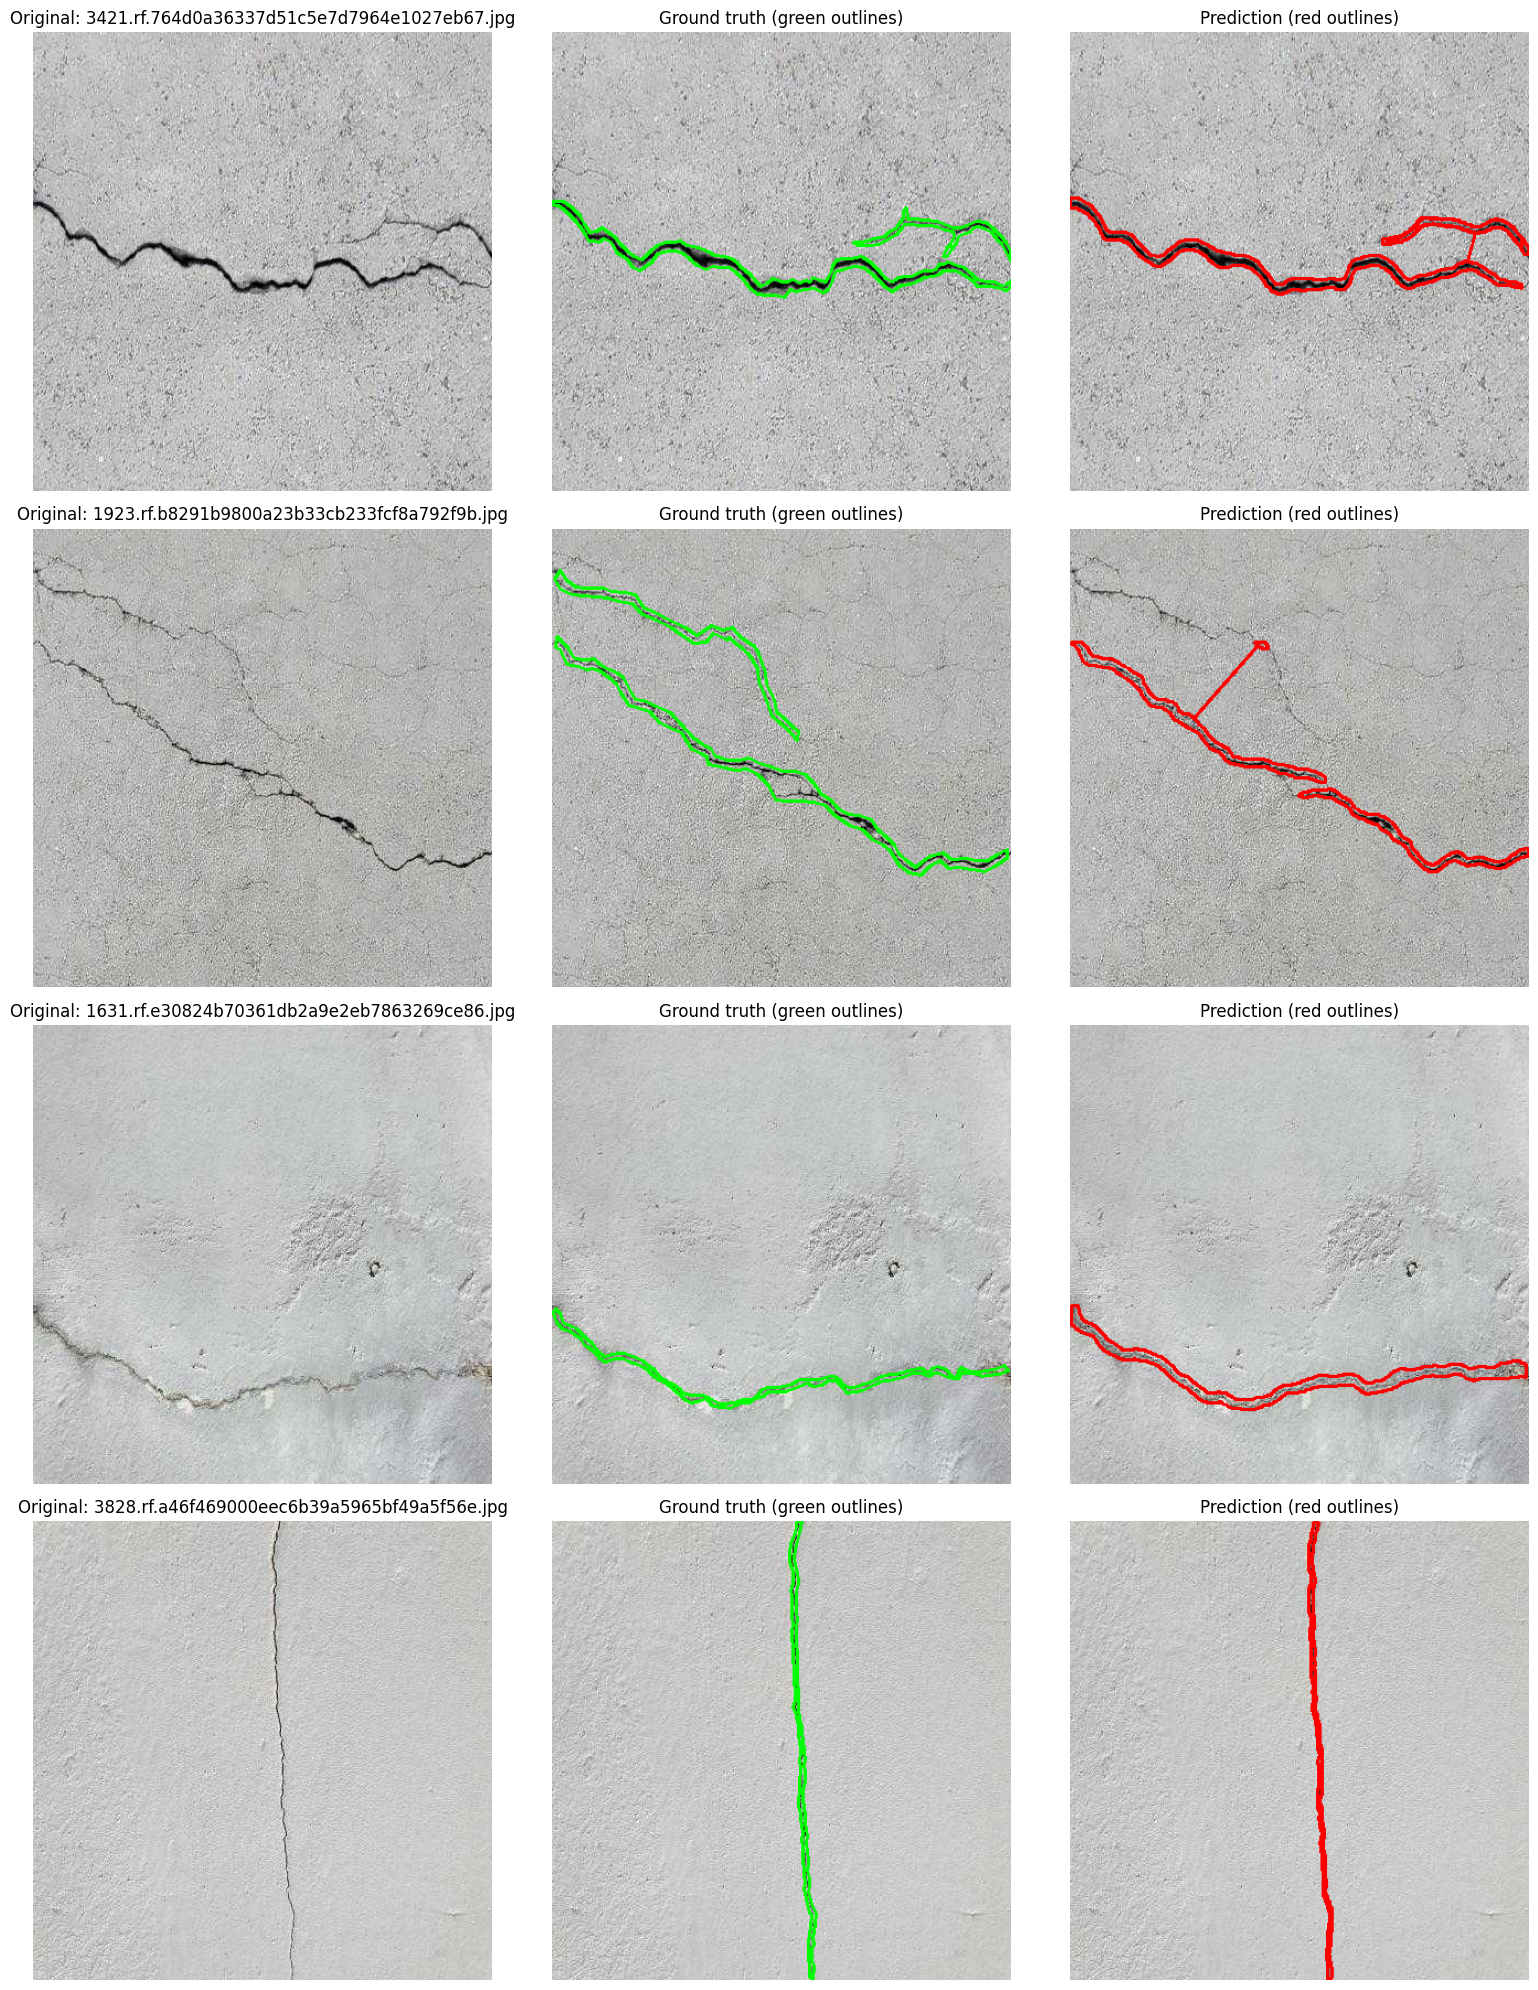

In [13]:
# Visualize predictions against ground truth
# Find validation images
image_paths = sorted(
    path for path in VAL_IMAGES_DIR.iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
)

if not image_paths:
    raise FileNotFoundError(f"No validation images found in {VAL_IMAGES_DIR}")

# Use a fixed seed so the sample is reproducible
rng = random.Random(42)
sample_paths = rng.sample(image_paths, min(4, len(image_paths)))

fig, axes = plt.subplots(
    len(sample_paths), 3,
    figsize=(16, 5 * len(sample_paths)),
    squeeze=False
)

for row, image_path in enumerate(sample_paths):
    image_bgr = cv2.imread(str(image_path))

    if image_bgr is None:
        print(f"Skipping unreadable image: {image_path.name}")
        continue

    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    # Ground-truth polygon annotations in YOLO segmentation format
    label_path = VAL_LABELS_DIR / f"{image_path.stem}.txt"
    ground_truth = image_rgb.copy()

    if label_path.exists():
        height, width = image_rgb.shape[:2]

        with label_path.open("r") as file:
            for line in file:
                values = line.split()

                # Class ID followed by normalized polygon coordinates
                if len(values) < 7 or (len(values) - 1) % 2 != 0:
                    continue

                coordinates = np.asarray(
                    [float(value) for value in values[1:]],
                    dtype=np.float32
                ).reshape(-1, 2)

                coordinates[:, 0] *= width
                coordinates[:, 1] *= height
                polygon = np.round(coordinates).astype(np.int32)

                cv2.polylines(
                    ground_truth, [polygon],
                    isClosed=True, color=(0, 255, 0), thickness=2
                )

    # Model prediction
    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    predicted = image_rgb.copy()

    if result.masks is not None:
        for polygon in result.masks.xy:
            points = np.round(polygon).astype(np.int32)

            if len(points) >= 3:
                cv2.polylines(
                    predicted, [points],
                    isClosed=True, color=(255, 0, 0), thickness=2
                )

    axes[row, 0].imshow(image_rgb)
    axes[row, 0].set_title(f"Original: {image_path.name}")

    axes[row, 1].imshow(ground_truth)
    axes[row, 1].set_title("Ground truth (green outlines)")

    axes[row, 2].imshow(predicted)
    axes[row, 2].set_title("Prediction (red outlines)")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
# Inspect the raw prediction
# Inspect the first validation image in detail
image_path = sample_paths[0]

result = model.predict(
    source=str(image_path),
    imgsz=640,
    conf=0.25,
    verbose=False
)[0]

print("Image:", image_path.name)
print("Number of detected boxes:", len(result.boxes))

if result.boxes is not None and len(result.boxes) > 0:
    confidences = result.boxes.conf.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)

    for i, (class_id, confidence) in enumerate(zip(classes, confidences)):
        polygon_points = (
            len(result.masks.xy[i])
            if result.masks is not None
            else 0
        )

        print(
            f"Detection {i + 1}: "
            f"class={model.names[class_id]}, "
            f"confidence={confidence:.3f}, "
            f"polygon_points={polygon_points}"
        )
else:
    print("No detections found.")

Image: 3421.rf.764d0a36337d51c5e7d7964e1027eb67.jpg
Number of detected boxes: 2
Detection 1: class=crack, confidence=0.766, polygon_points=802
Detection 2: class=crack, confidence=0.330, polygon_points=188


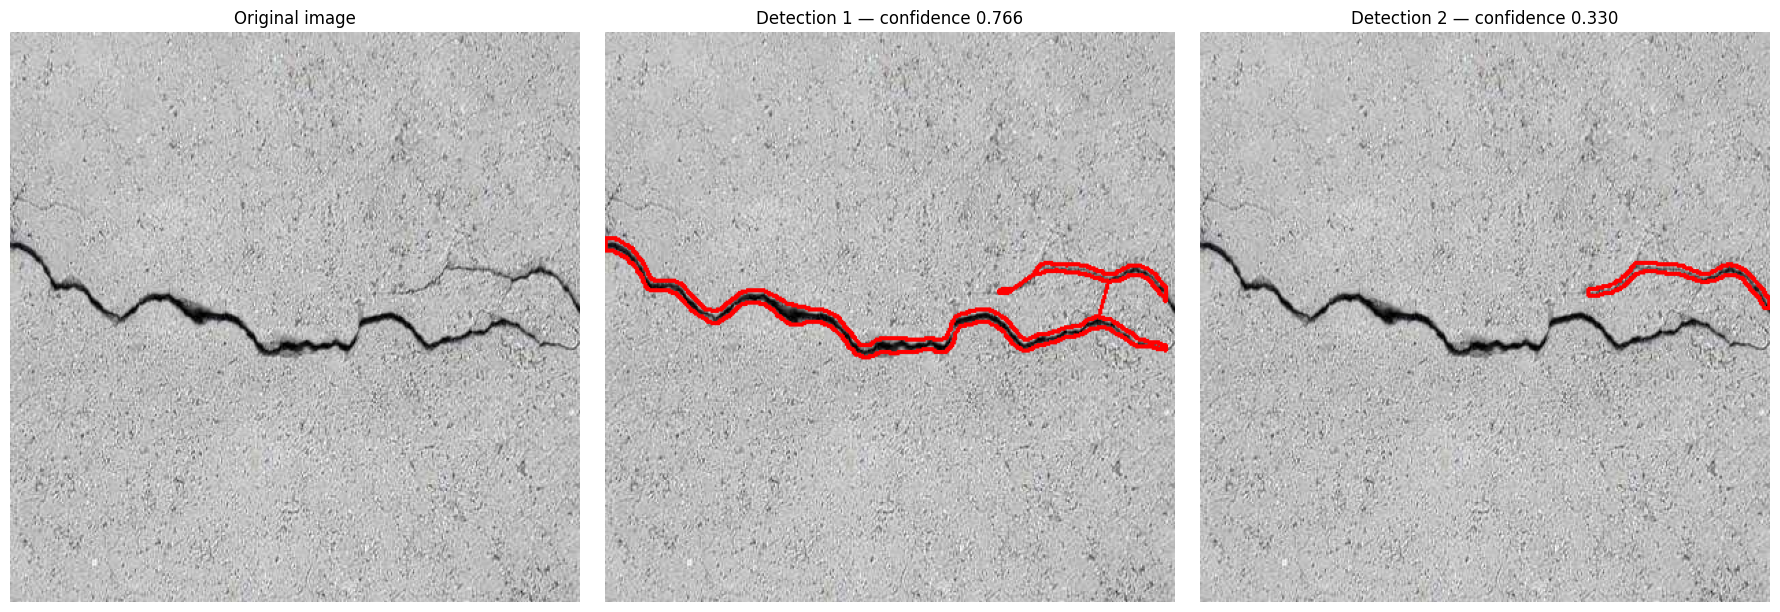

In [15]:
# Display each prediction separately
image_bgr = cv2.imread(str(image_path))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

num_detections = len(result.boxes)

fig, axes = plt.subplots(
    1, num_detections + 1,
    figsize=(6 * (num_detections + 1), 6)
)

axes[0].imshow(image_rgb)
axes[0].set_title("Original image")
axes[0].axis("off")

if result.masks is not None:
    for i, polygon in enumerate(result.masks.xy):
        individual_image = image_rgb.copy()
        points = np.round(polygon).astype(np.int32)

        if len(points) >= 3:
            cv2.polylines(
                individual_image,
                [points],
                isClosed=True,
                color=(255, 0, 0),
                thickness=2
            )

        confidence = result.boxes.conf[i].item()

        axes[i + 1].imshow(individual_image)
        axes[i + 1].set_title(
            f"Detection {i + 1} — confidence {confidence:.3f}"
        )
        axes[i + 1].axis("off")

plt.tight_layout()
plt.show()

In [17]:
# Measure the effect of confidence thresholds
confidence_thresholds = [0.25, 0.40, 0.60]
threshold_results = defaultdict(list)

# Reuse the same validation sample for a fair comparison
for image_path in sample_paths:
    for threshold in confidence_thresholds:
        prediction = model.predict(
            source=str(image_path),
            imgsz=640,
            conf=threshold,
            verbose=False
        )[0]

        count = len(prediction.boxes)
        threshold_results[threshold].append(count)

print("Detection counts across the same validation sample")
print("-" * 48)

for threshold in confidence_thresholds:
    counts = threshold_results[threshold]

    print(
        f"Confidence >= {threshold:.2f}: "
        f"total detections = {sum(counts)}, "
        f"per-image counts = {counts}"
    )

Detection counts across the same validation sample
------------------------------------------------
Confidence >= 0.25: total detections = 6, per-image counts = [2, 2, 1, 1]
Confidence >= 0.40: total detections = 5, per-image counts = [1, 2, 1, 1]
Confidence >= 0.60: total detections = 4, per-image counts = [1, 1, 1, 1]


In [18]:
# Evaluate the full validation set at different thresholds
confidence_thresholds = [0.001, 0.10, 0.25]

threshold_metrics = []

for threshold in confidence_thresholds:
    metrics = model.val(
        data=str(VAL_DATA_YAML),
        split="val",
        imgsz=640,
        batch=8,
        conf=threshold,
        plots=False,
        verbose=False
    )

    threshold_metrics.append({
        "confidence": threshold,
        "box_precision": metrics.box.mp,
        "box_recall": metrics.box.mr,
        "box_mAP50": metrics.box.map50,
        "mask_precision": metrics.seg.mp,
        "mask_recall": metrics.seg.mr,
        "mask_mAP50": metrics.seg.map50,
        "mask_mAP50_95": metrics.seg.map,
    })

threshold_df = pd.DataFrame(threshold_metrics)

display(
    threshold_df.round(4)
)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,849,467 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 576.9±205.8 MB/s, size: 19.0 KB)
val: Scanning /content/crack-seg/labels/val.cache... 200 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 44.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 6.2it/s 4.0s
                   all        200        249      0.835      0.731      0.788      0.596      0.729      0.639      0.635      0.215
Speed: 1.4ms preprocess, 7.6ms inference, 0.0ms loss, 3.1ms postprocess per image
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,849,467 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1188.1±

,confidence,box_precision,box_recall,box_mAP50,mask_precision,mask_recall,mask_mAP50,mask_mAP50_95
0,0.001,0.8347,0.7309,0.7883,0.7288,0.6386,0.6345,0.2155
1,0.100,0.8347,0.7309,0.7627,0.7288,0.6386,0.6105,0.2089
2,0.250,0.8347,0.7309,0.7393,0.7288,0.6386,0.5851,0.2030


In [19]:
# Save validation metrics to Google Drive
EVALUATION_DIR = (
    Path("/content/drive/MyDrive/CrackVision")
    / "evaluation-results"
)

EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

# Save the confidence-threshold experiment if its table exists.
if "threshold_df" in globals():
    threshold_path = EVALUATION_DIR / "confidence-threshold-comparison.csv"
    threshold_df.to_csv(threshold_path, index=False)
    print("Saved threshold comparison:", threshold_path)
else:
    print("Threshold comparison not found; skipping that file.")

# Save the main validation metrics separately.
validation_summary = pd.DataFrame([{
    "split": "validation",
    "images": 200,
    "instances": 249,
    "box_mAP50": 0.7883,
    "box_mAP50_95": 0.5958,
    "mask_mAP50": 0.6345,
    "mask_mAP50_95": 0.2155,
}])

summary_path = EVALUATION_DIR / "validation-summary.csv"
validation_summary.to_csv(summary_path, index=False)

print("\nSaved validation summary:", summary_path)
display(validation_summary)

Saved threshold comparison: /content/drive/MyDrive/CrackVision/evaluation-results/confidence-threshold-comparison.csv

Saved validation summary: /content/drive/MyDrive/CrackVision/evaluation-results/validation-summary.csv


,split,images,instances,box_mAP50,box_mAP50_95,mask_mAP50,mask_mAP50_95
0,validation,200,249,0.7883,0.5958,0.6345,0.2155


Looking for plots in: /content/drive/MyDrive/CrackVision/evaluation-results/validation-evaluation

BoxF1_curve.png


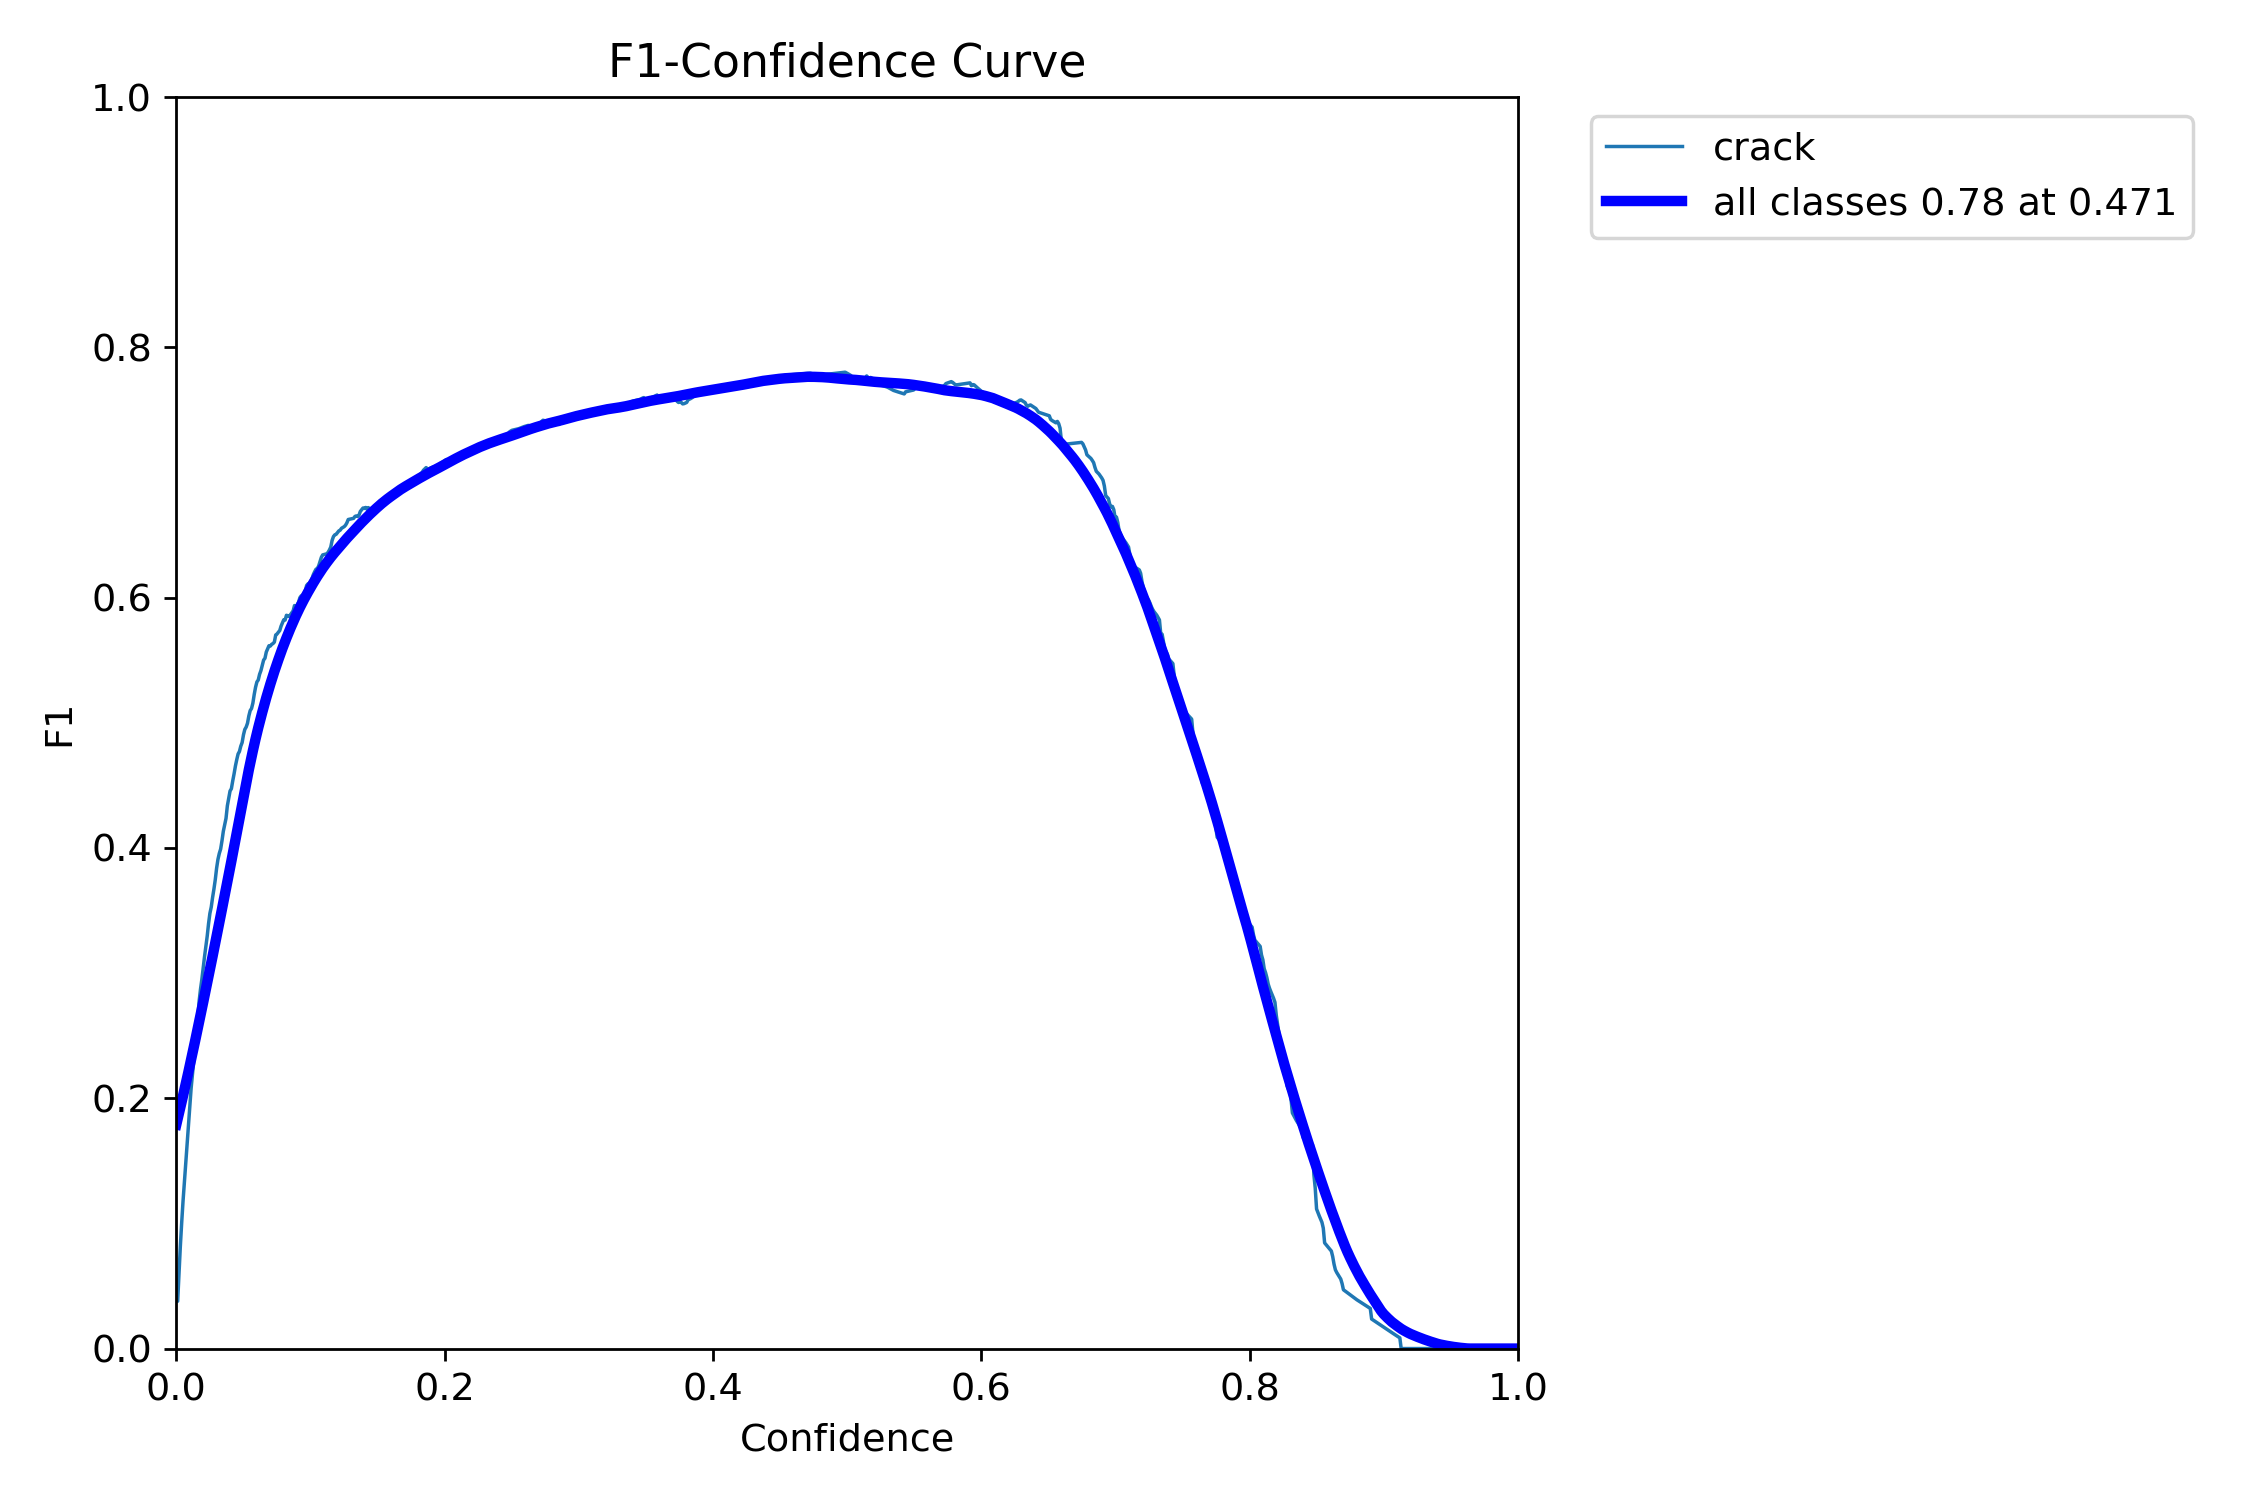


BoxPR_curve.png


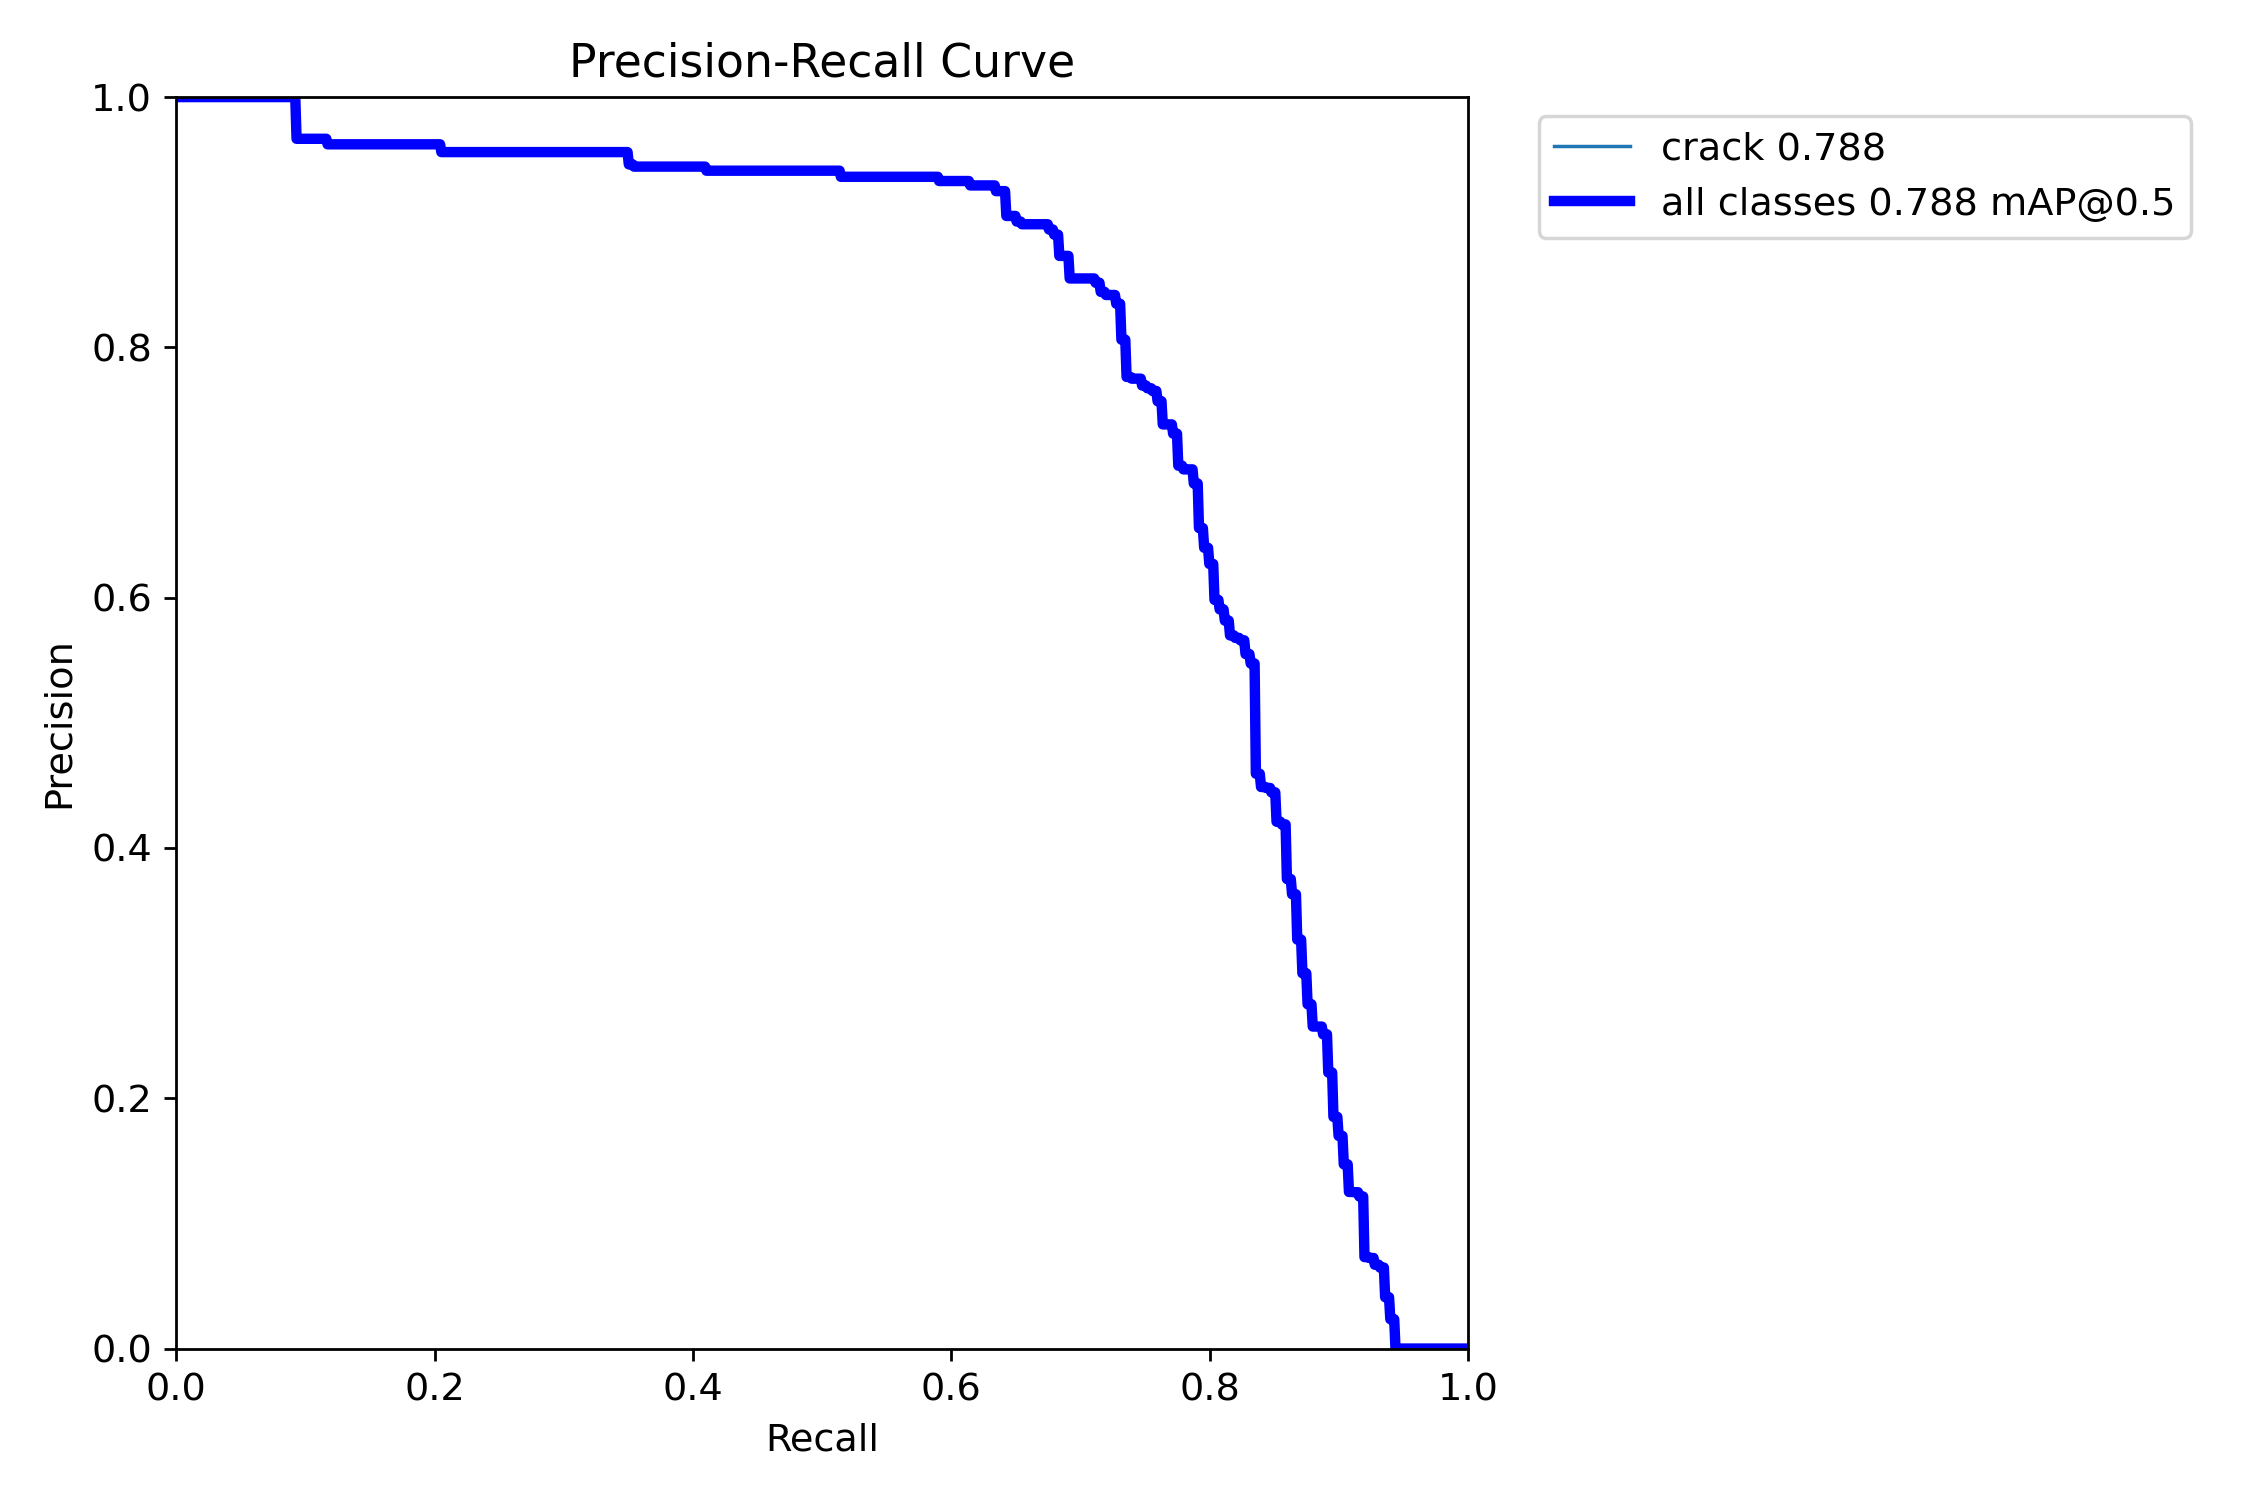


BoxP_curve.png


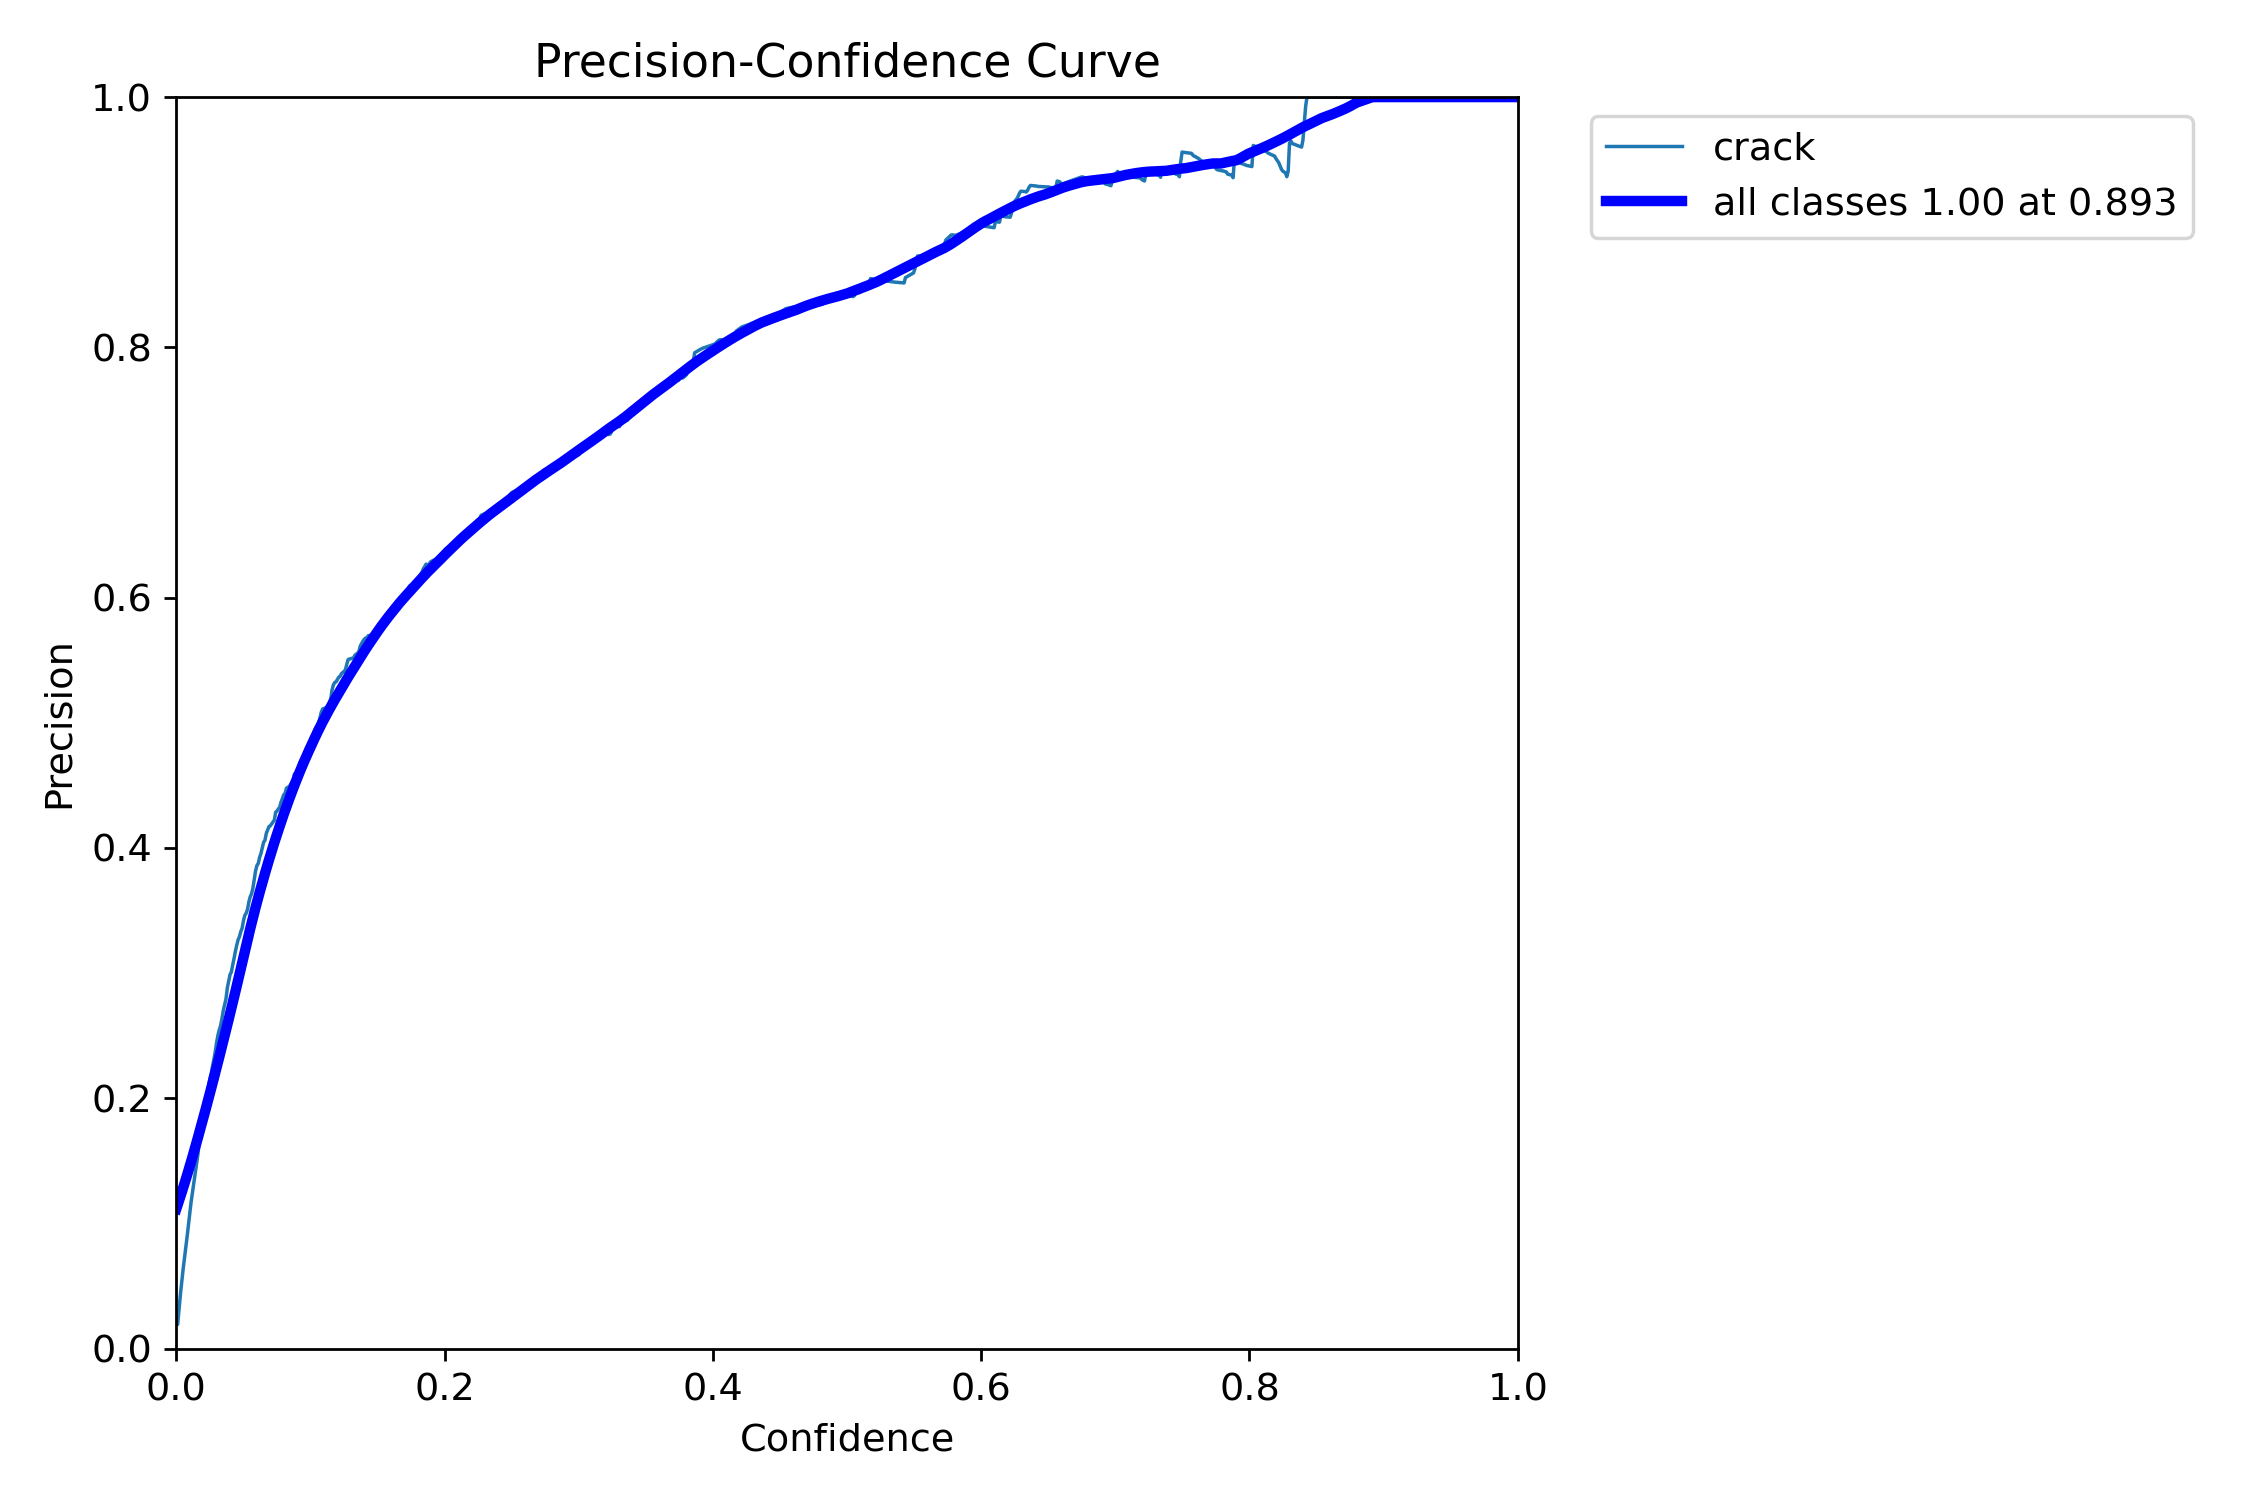


BoxR_curve.png


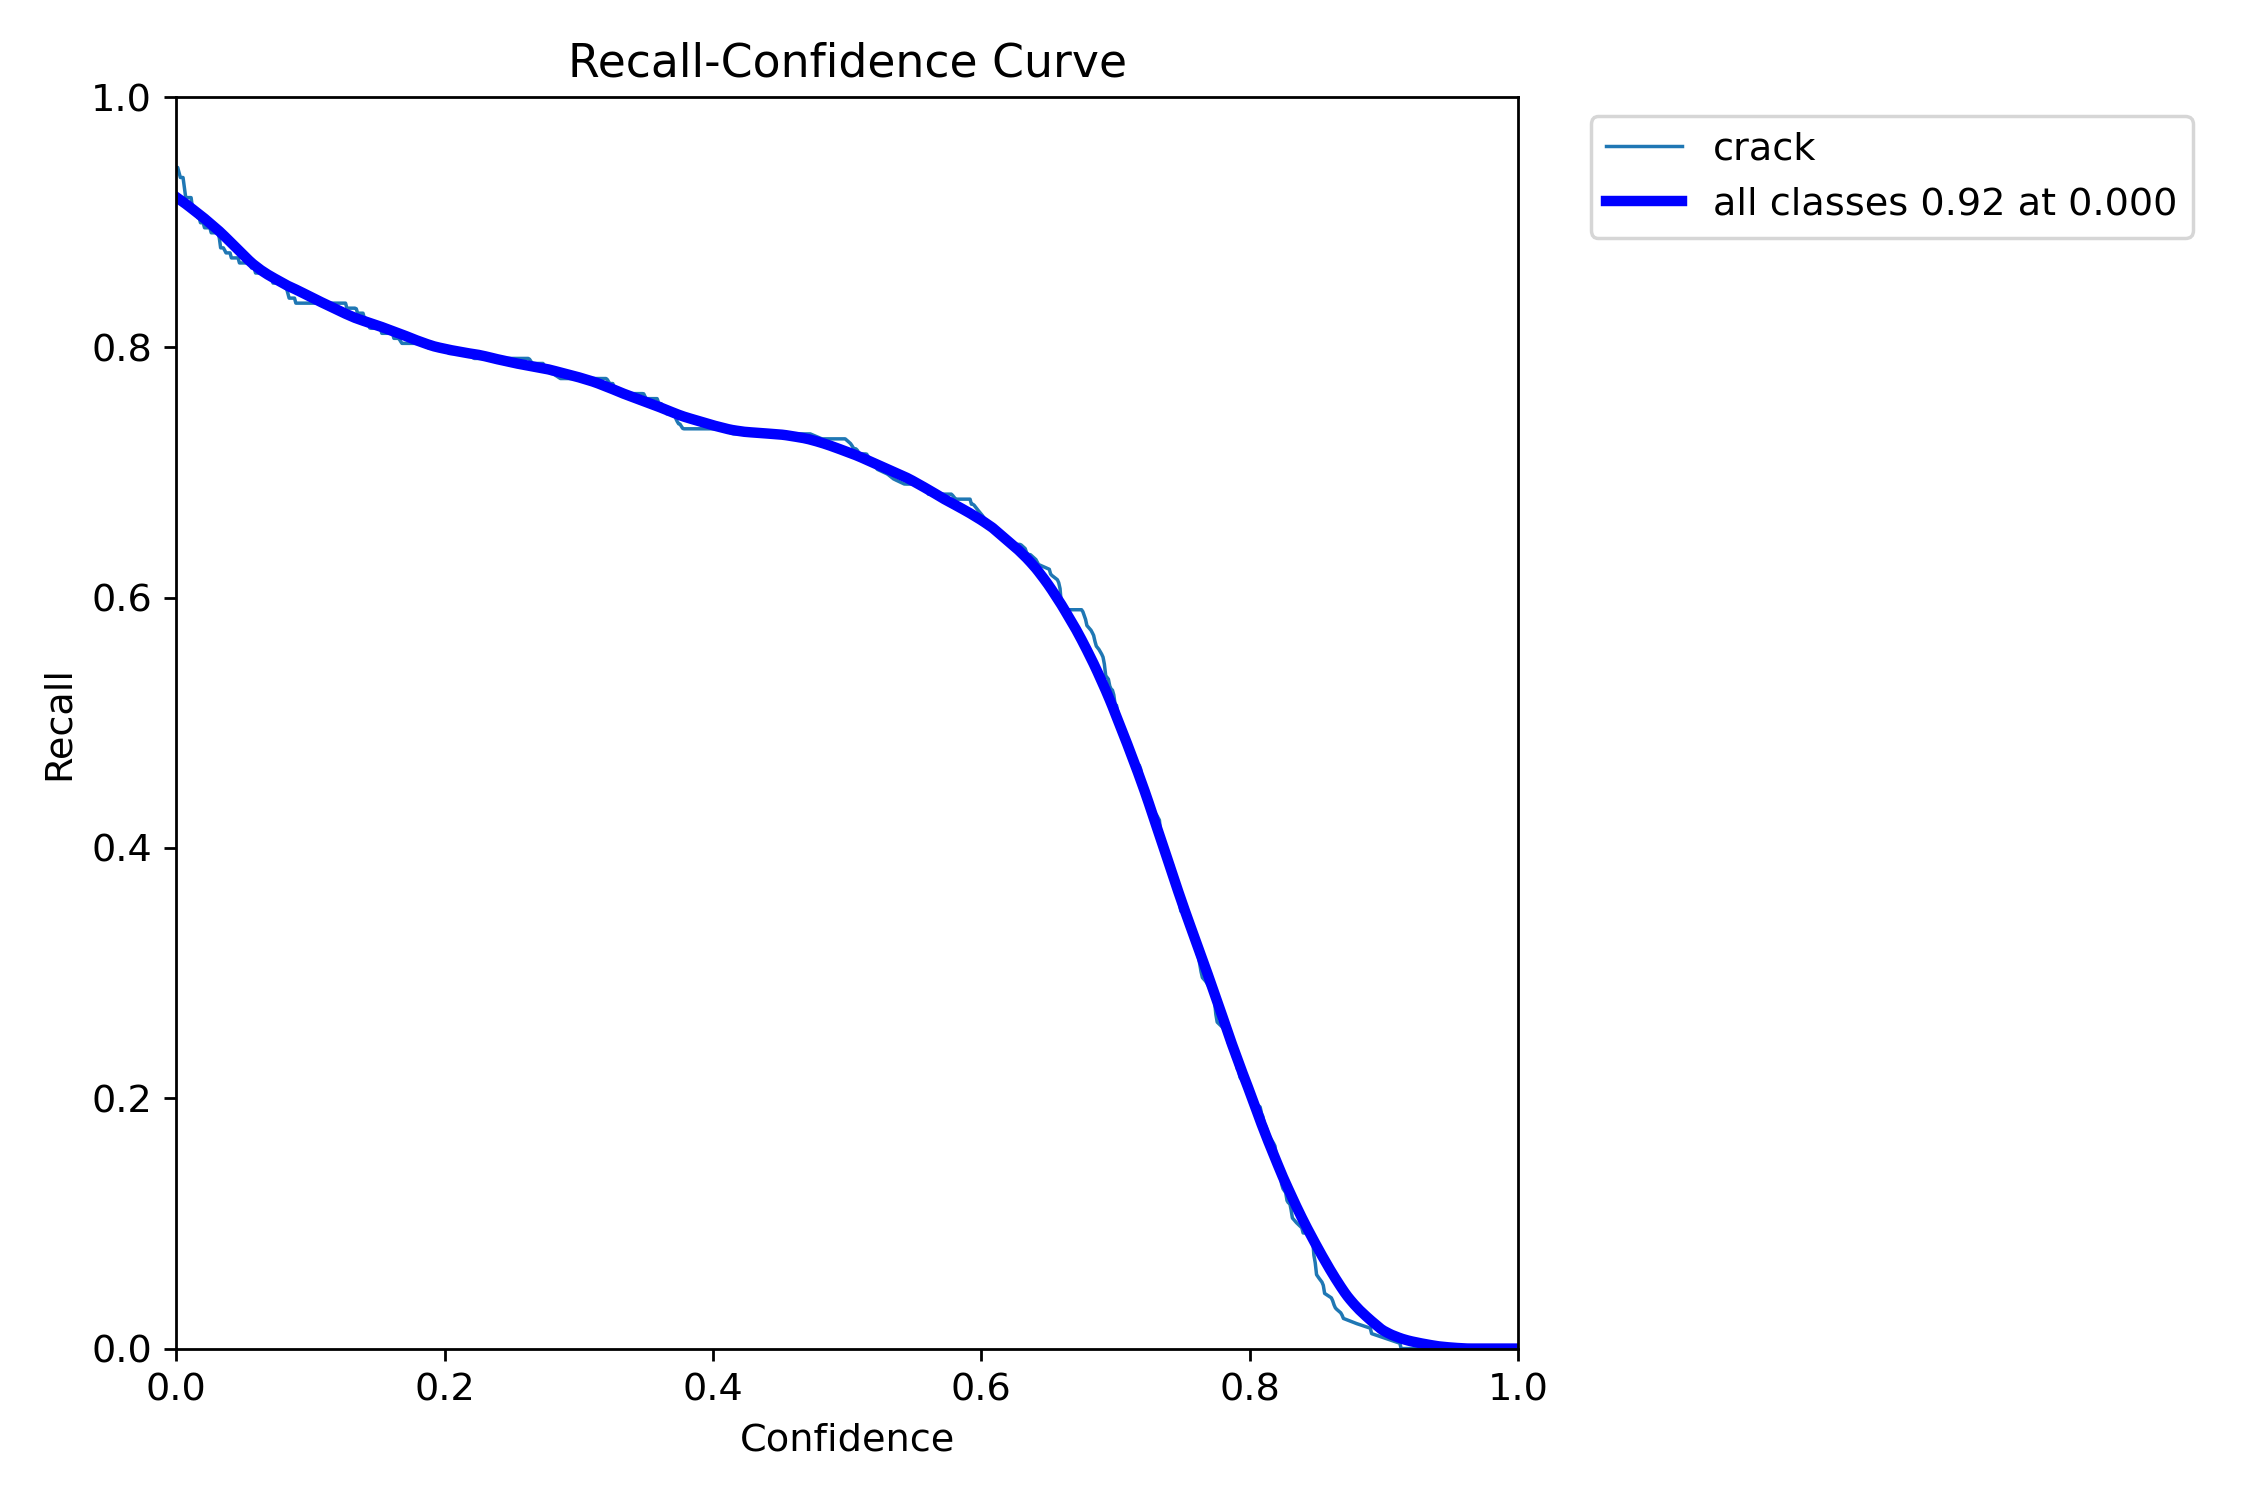


MaskF1_curve.png


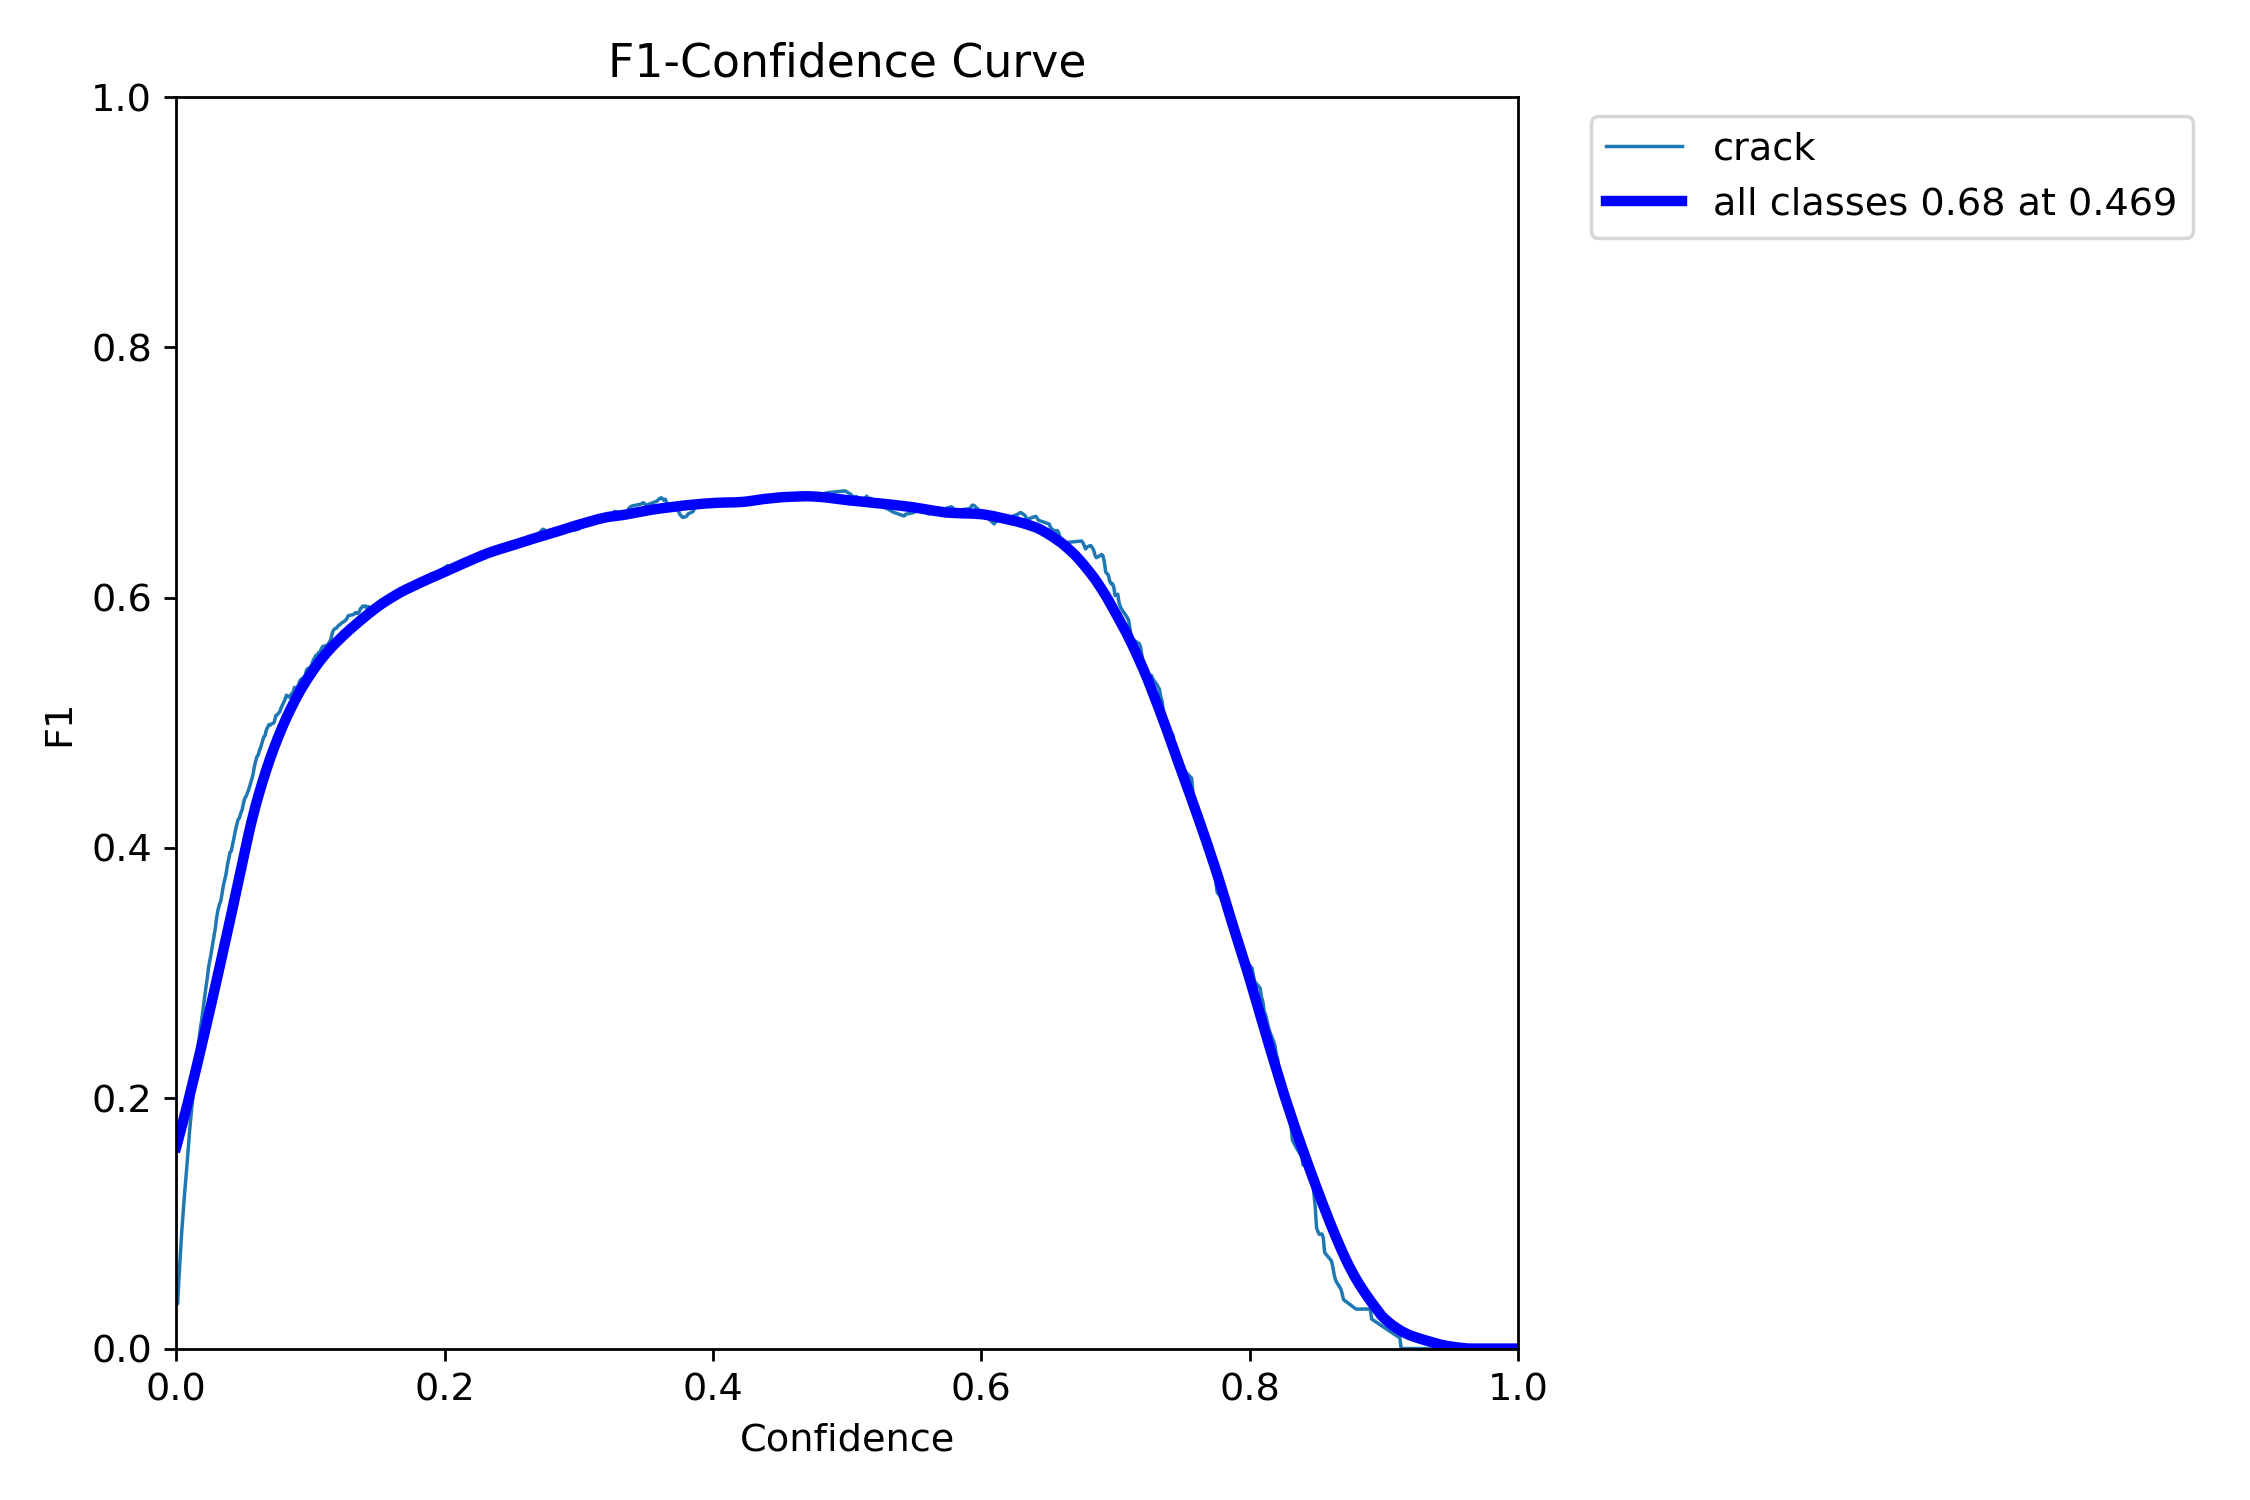


MaskPR_curve.png


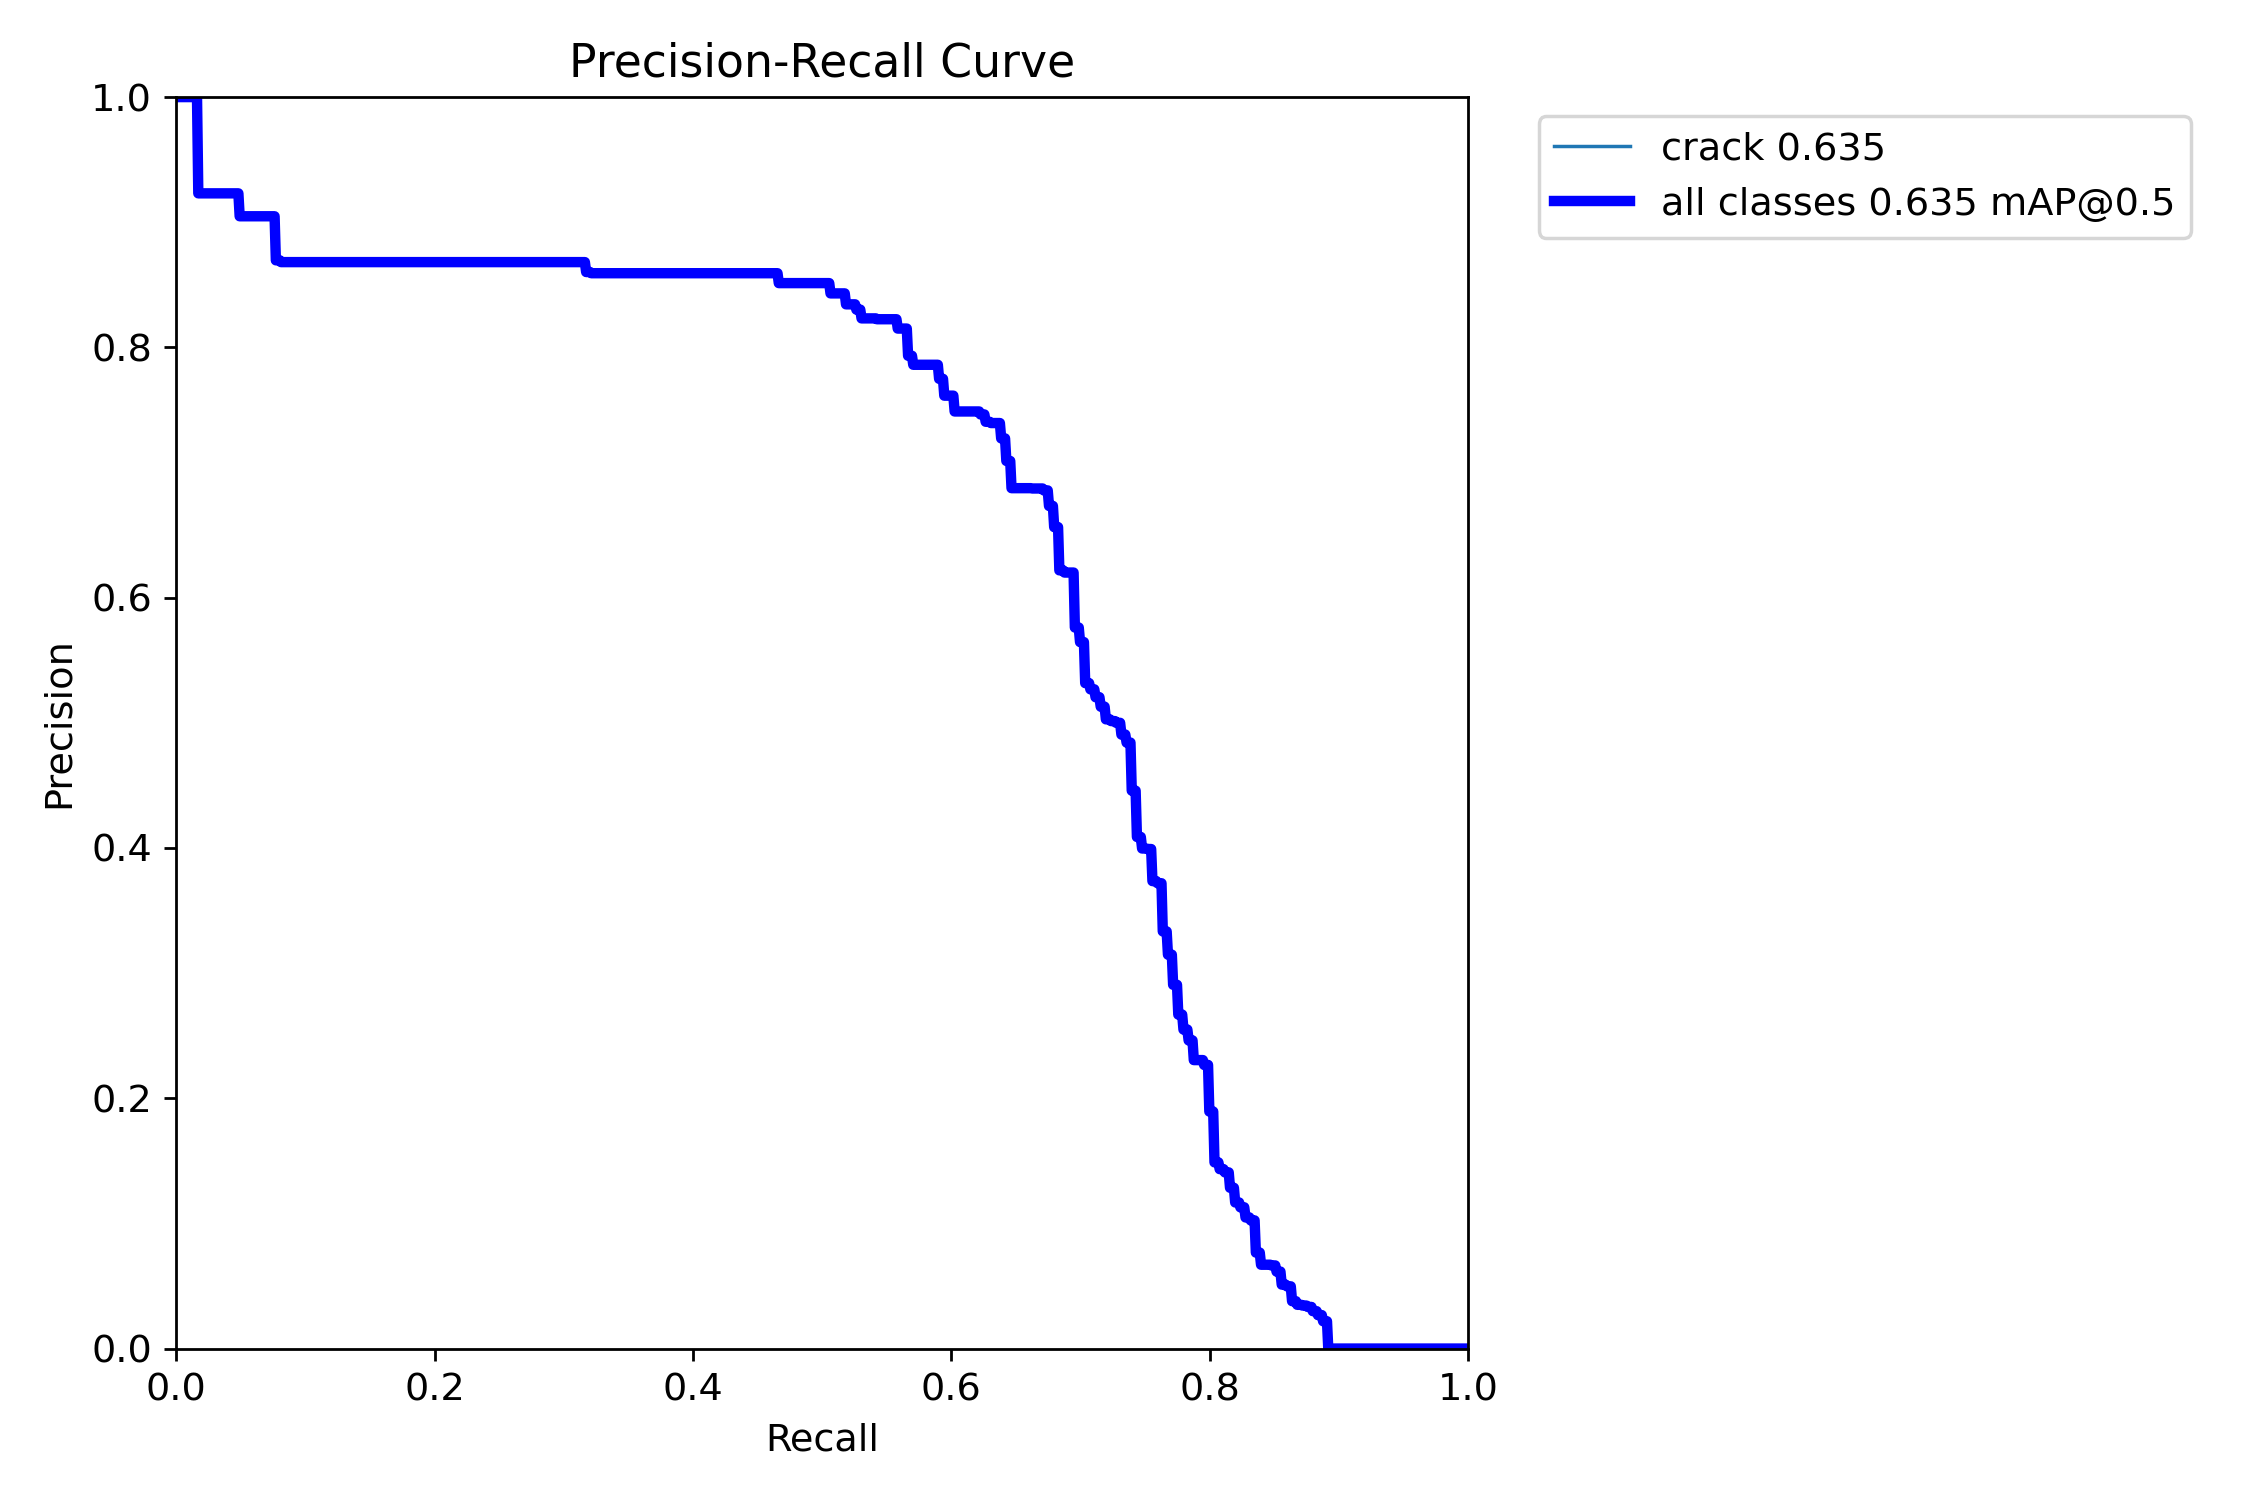


MaskP_curve.png


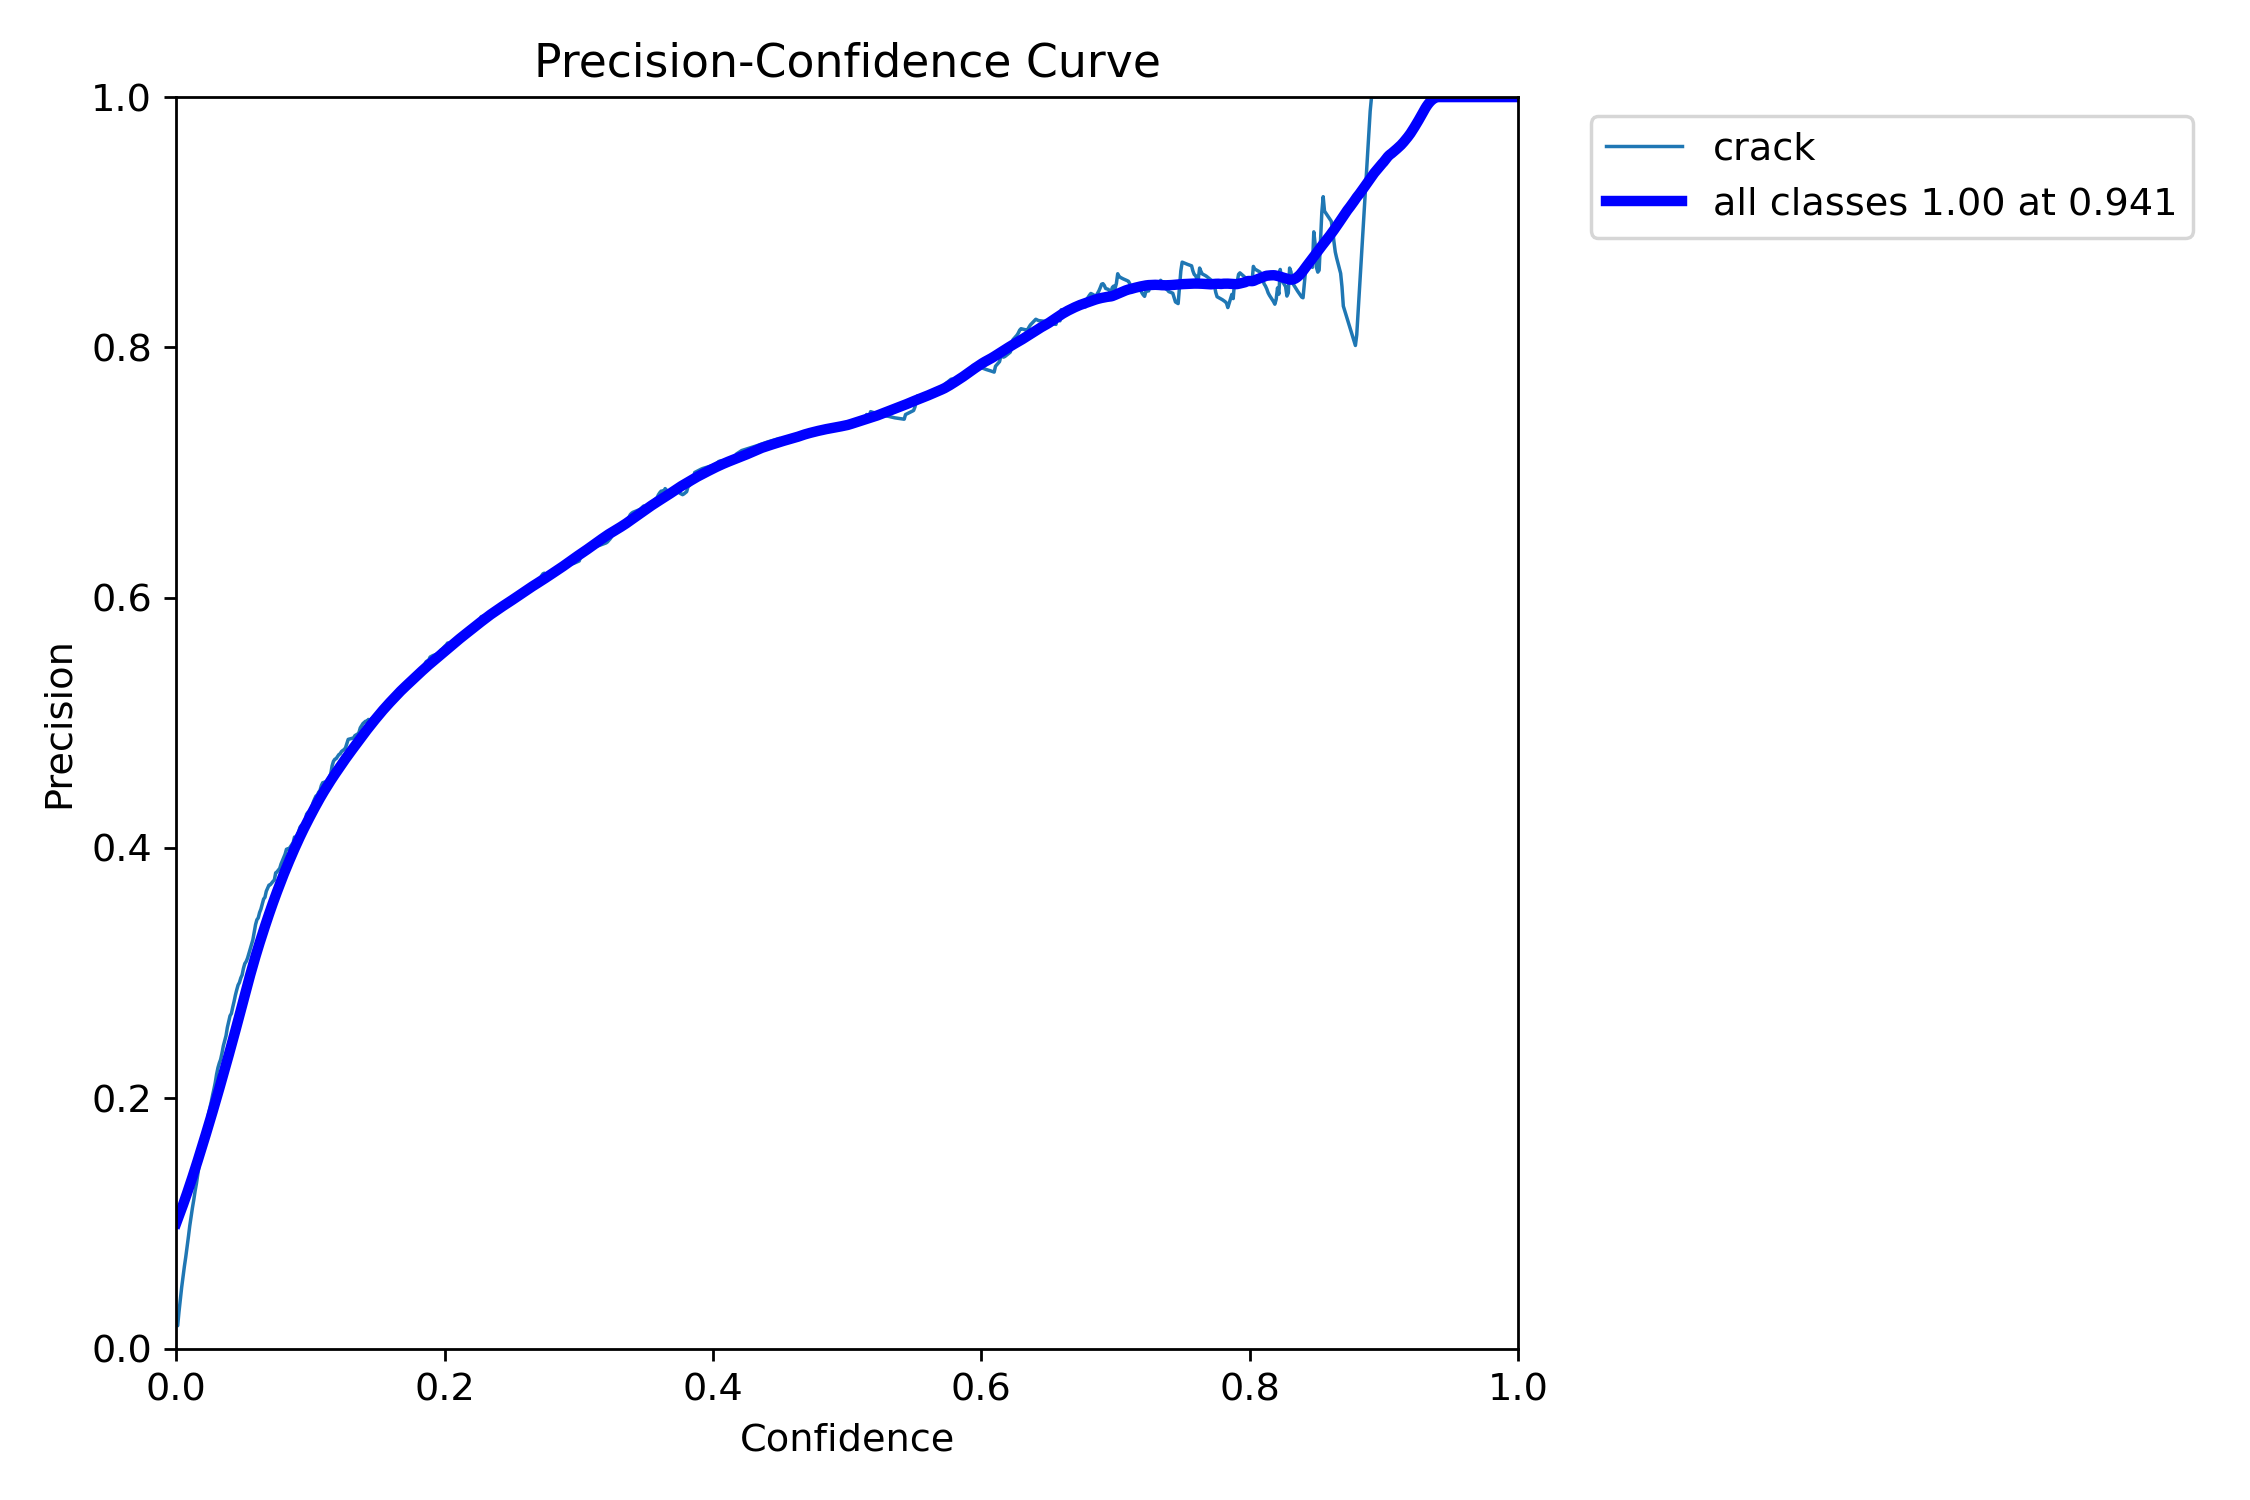


MaskR_curve.png


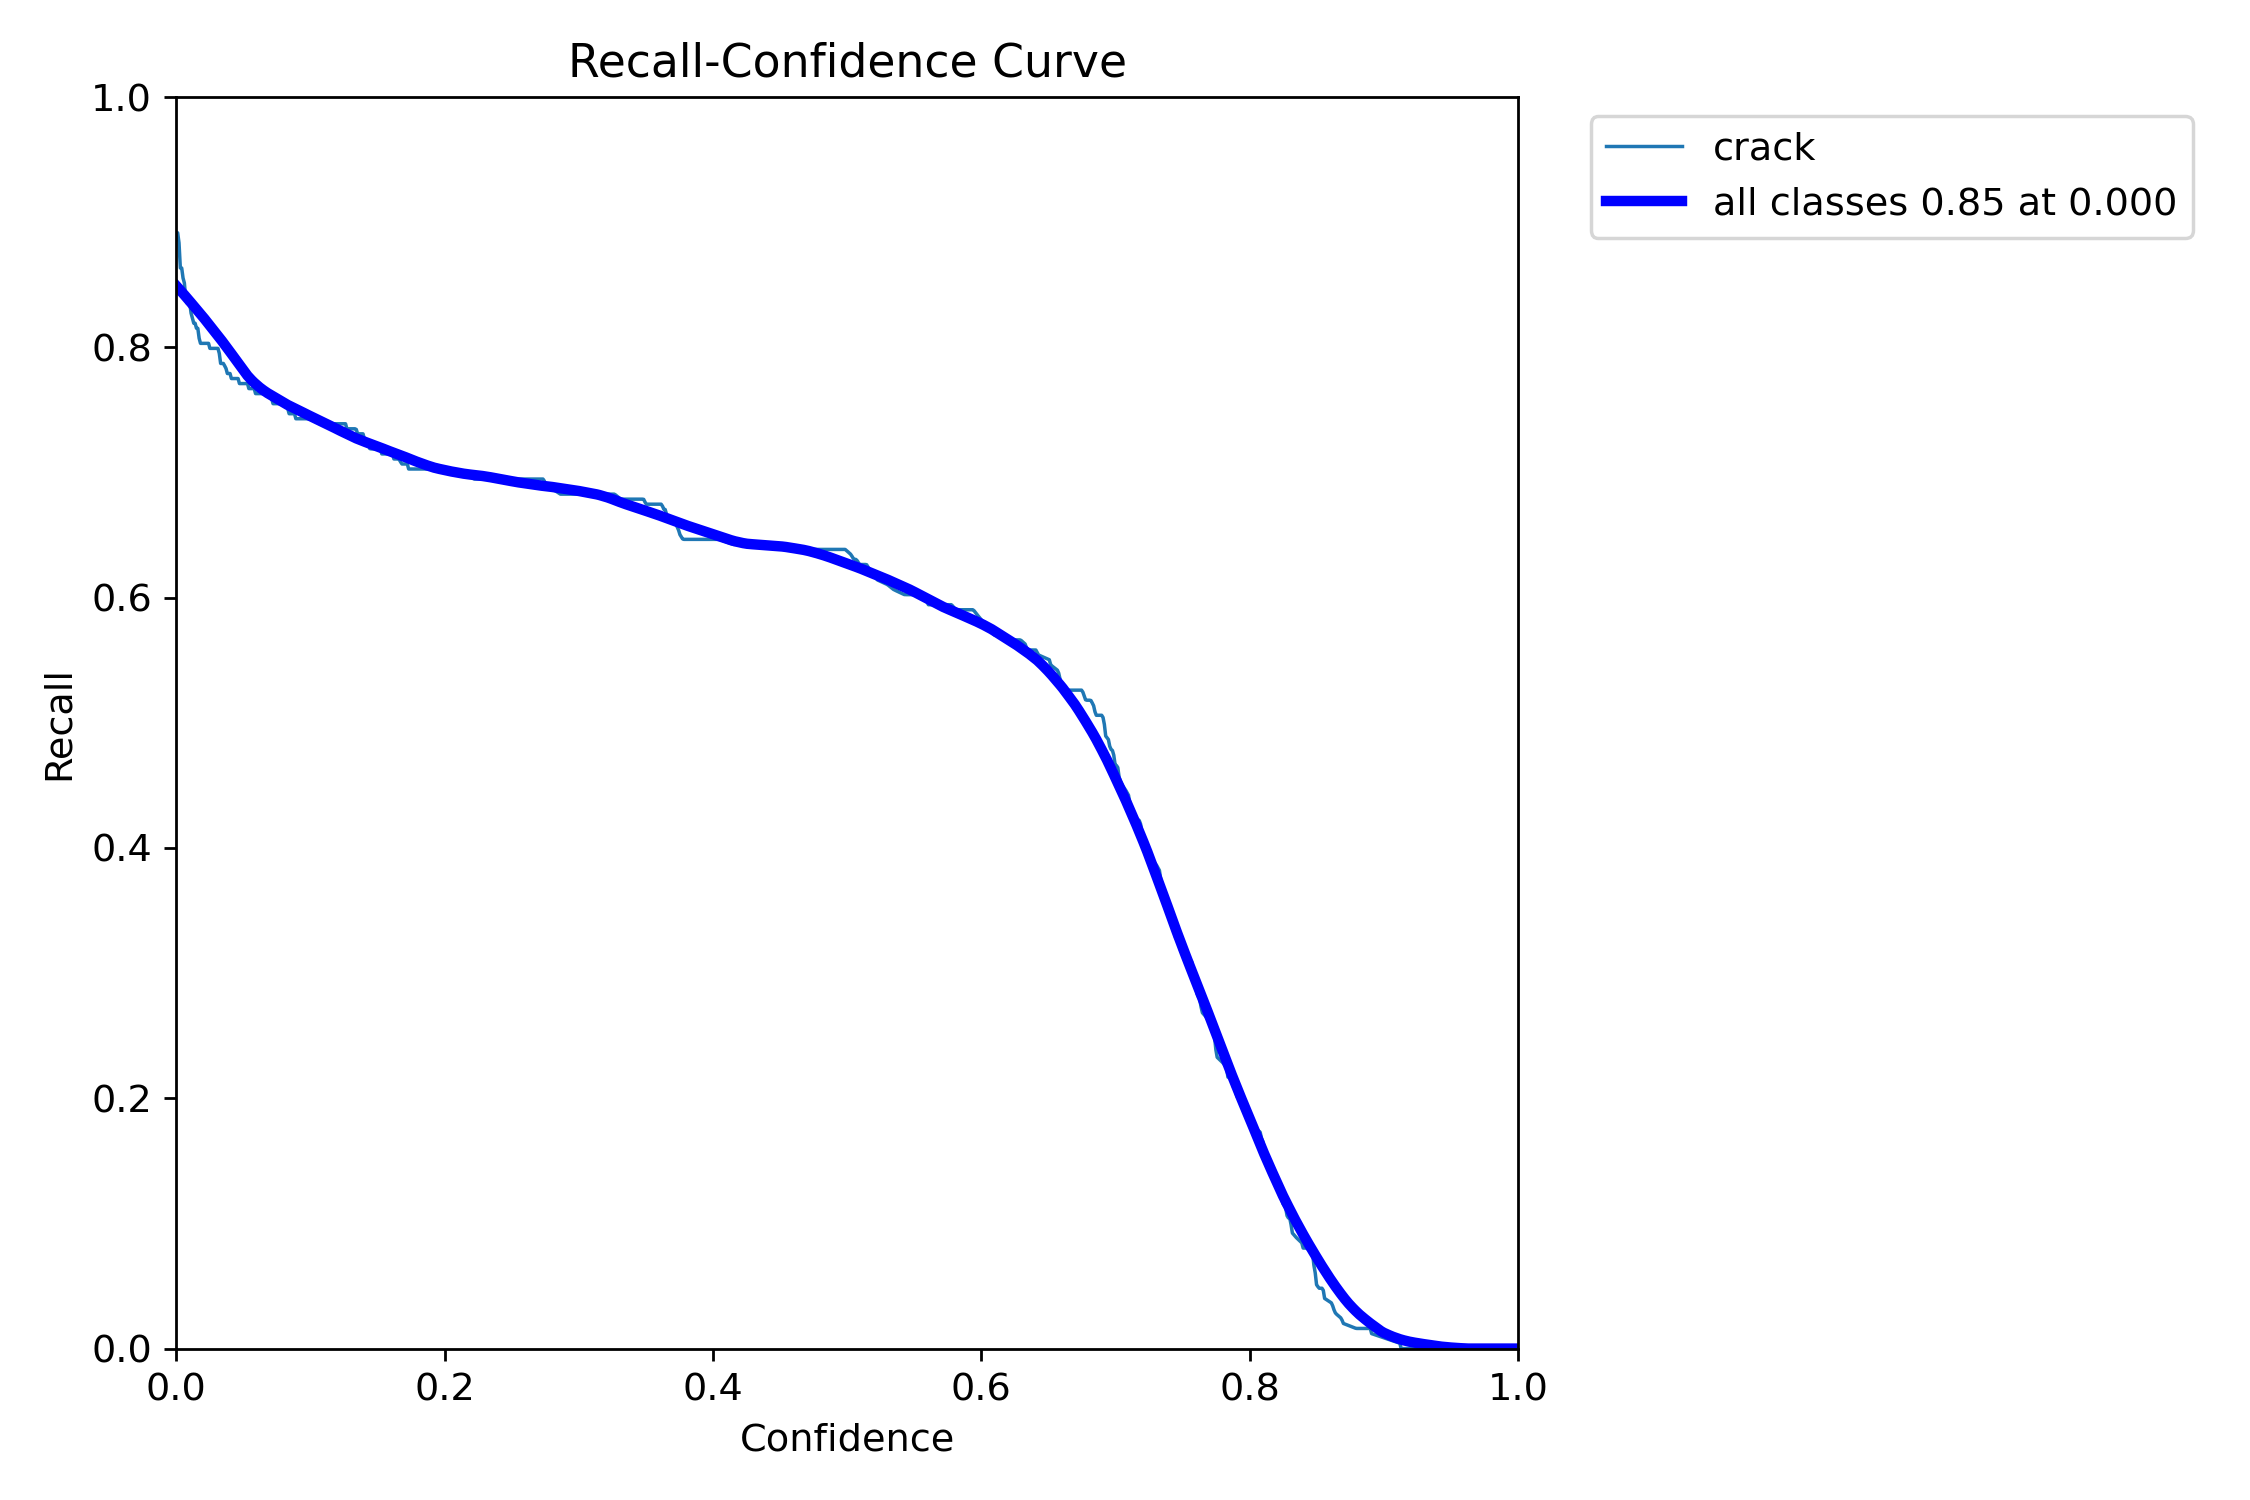


confusion_matrix.png


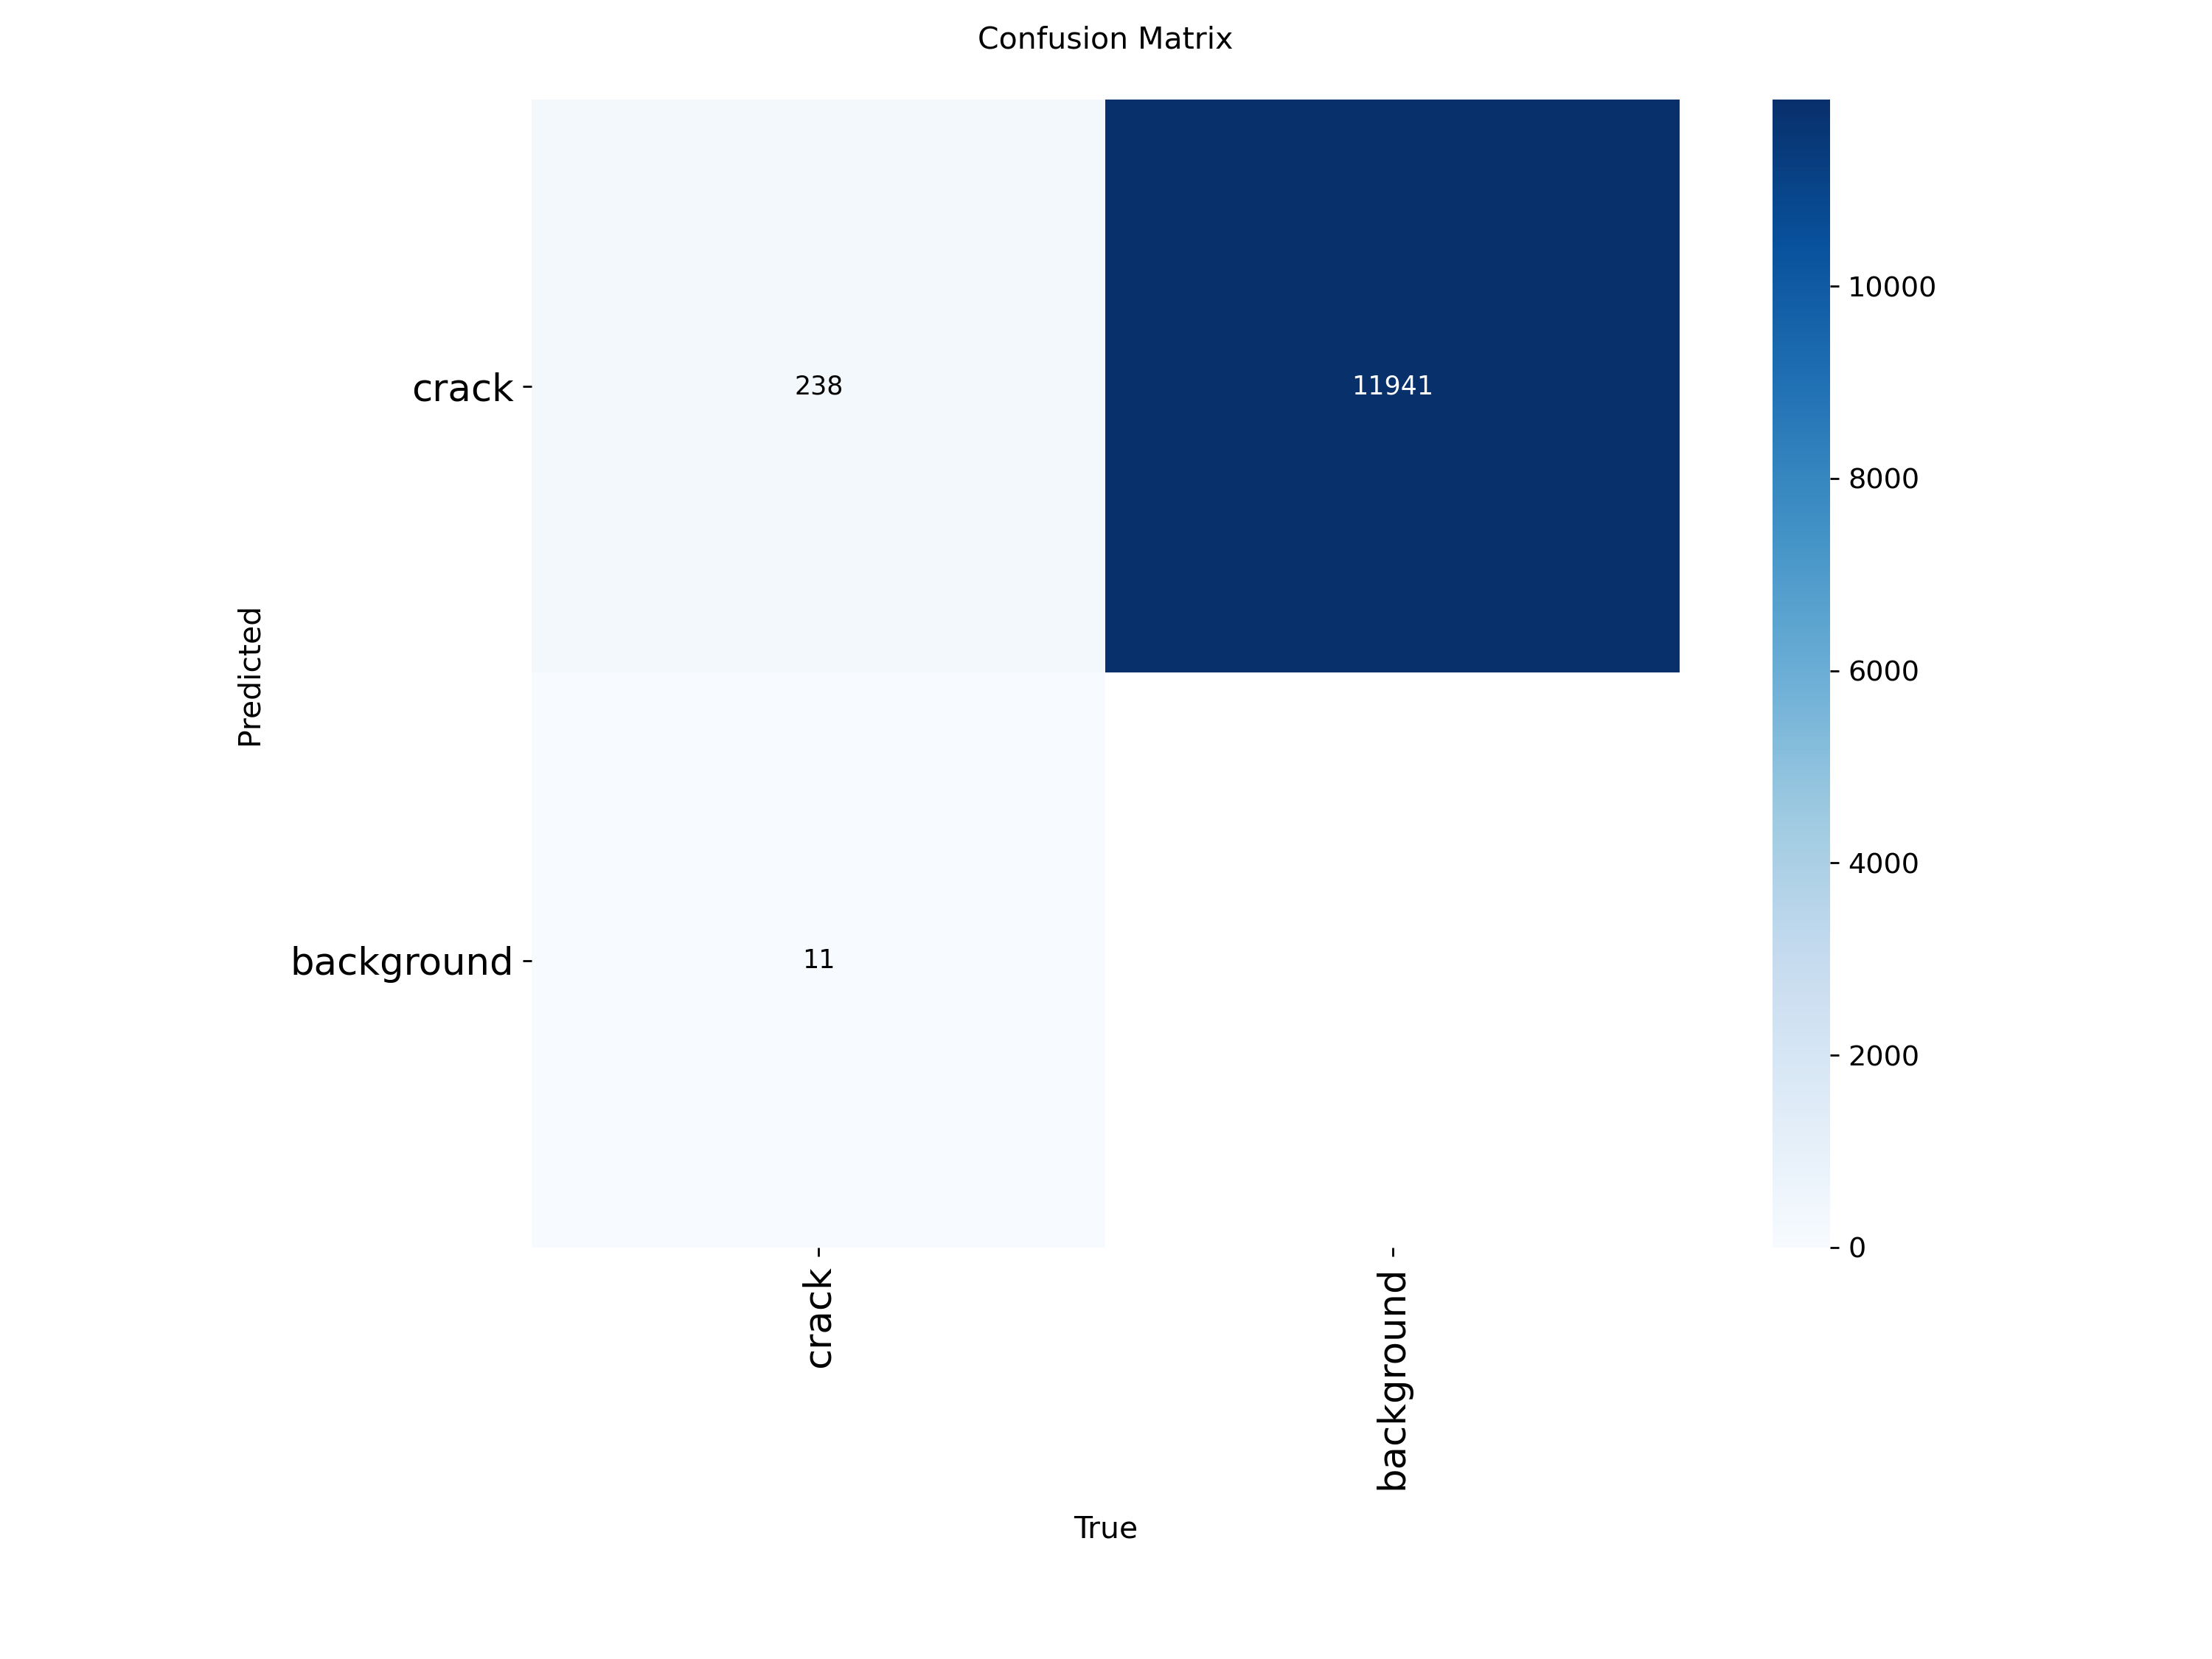


confusion_matrix_normalized.png


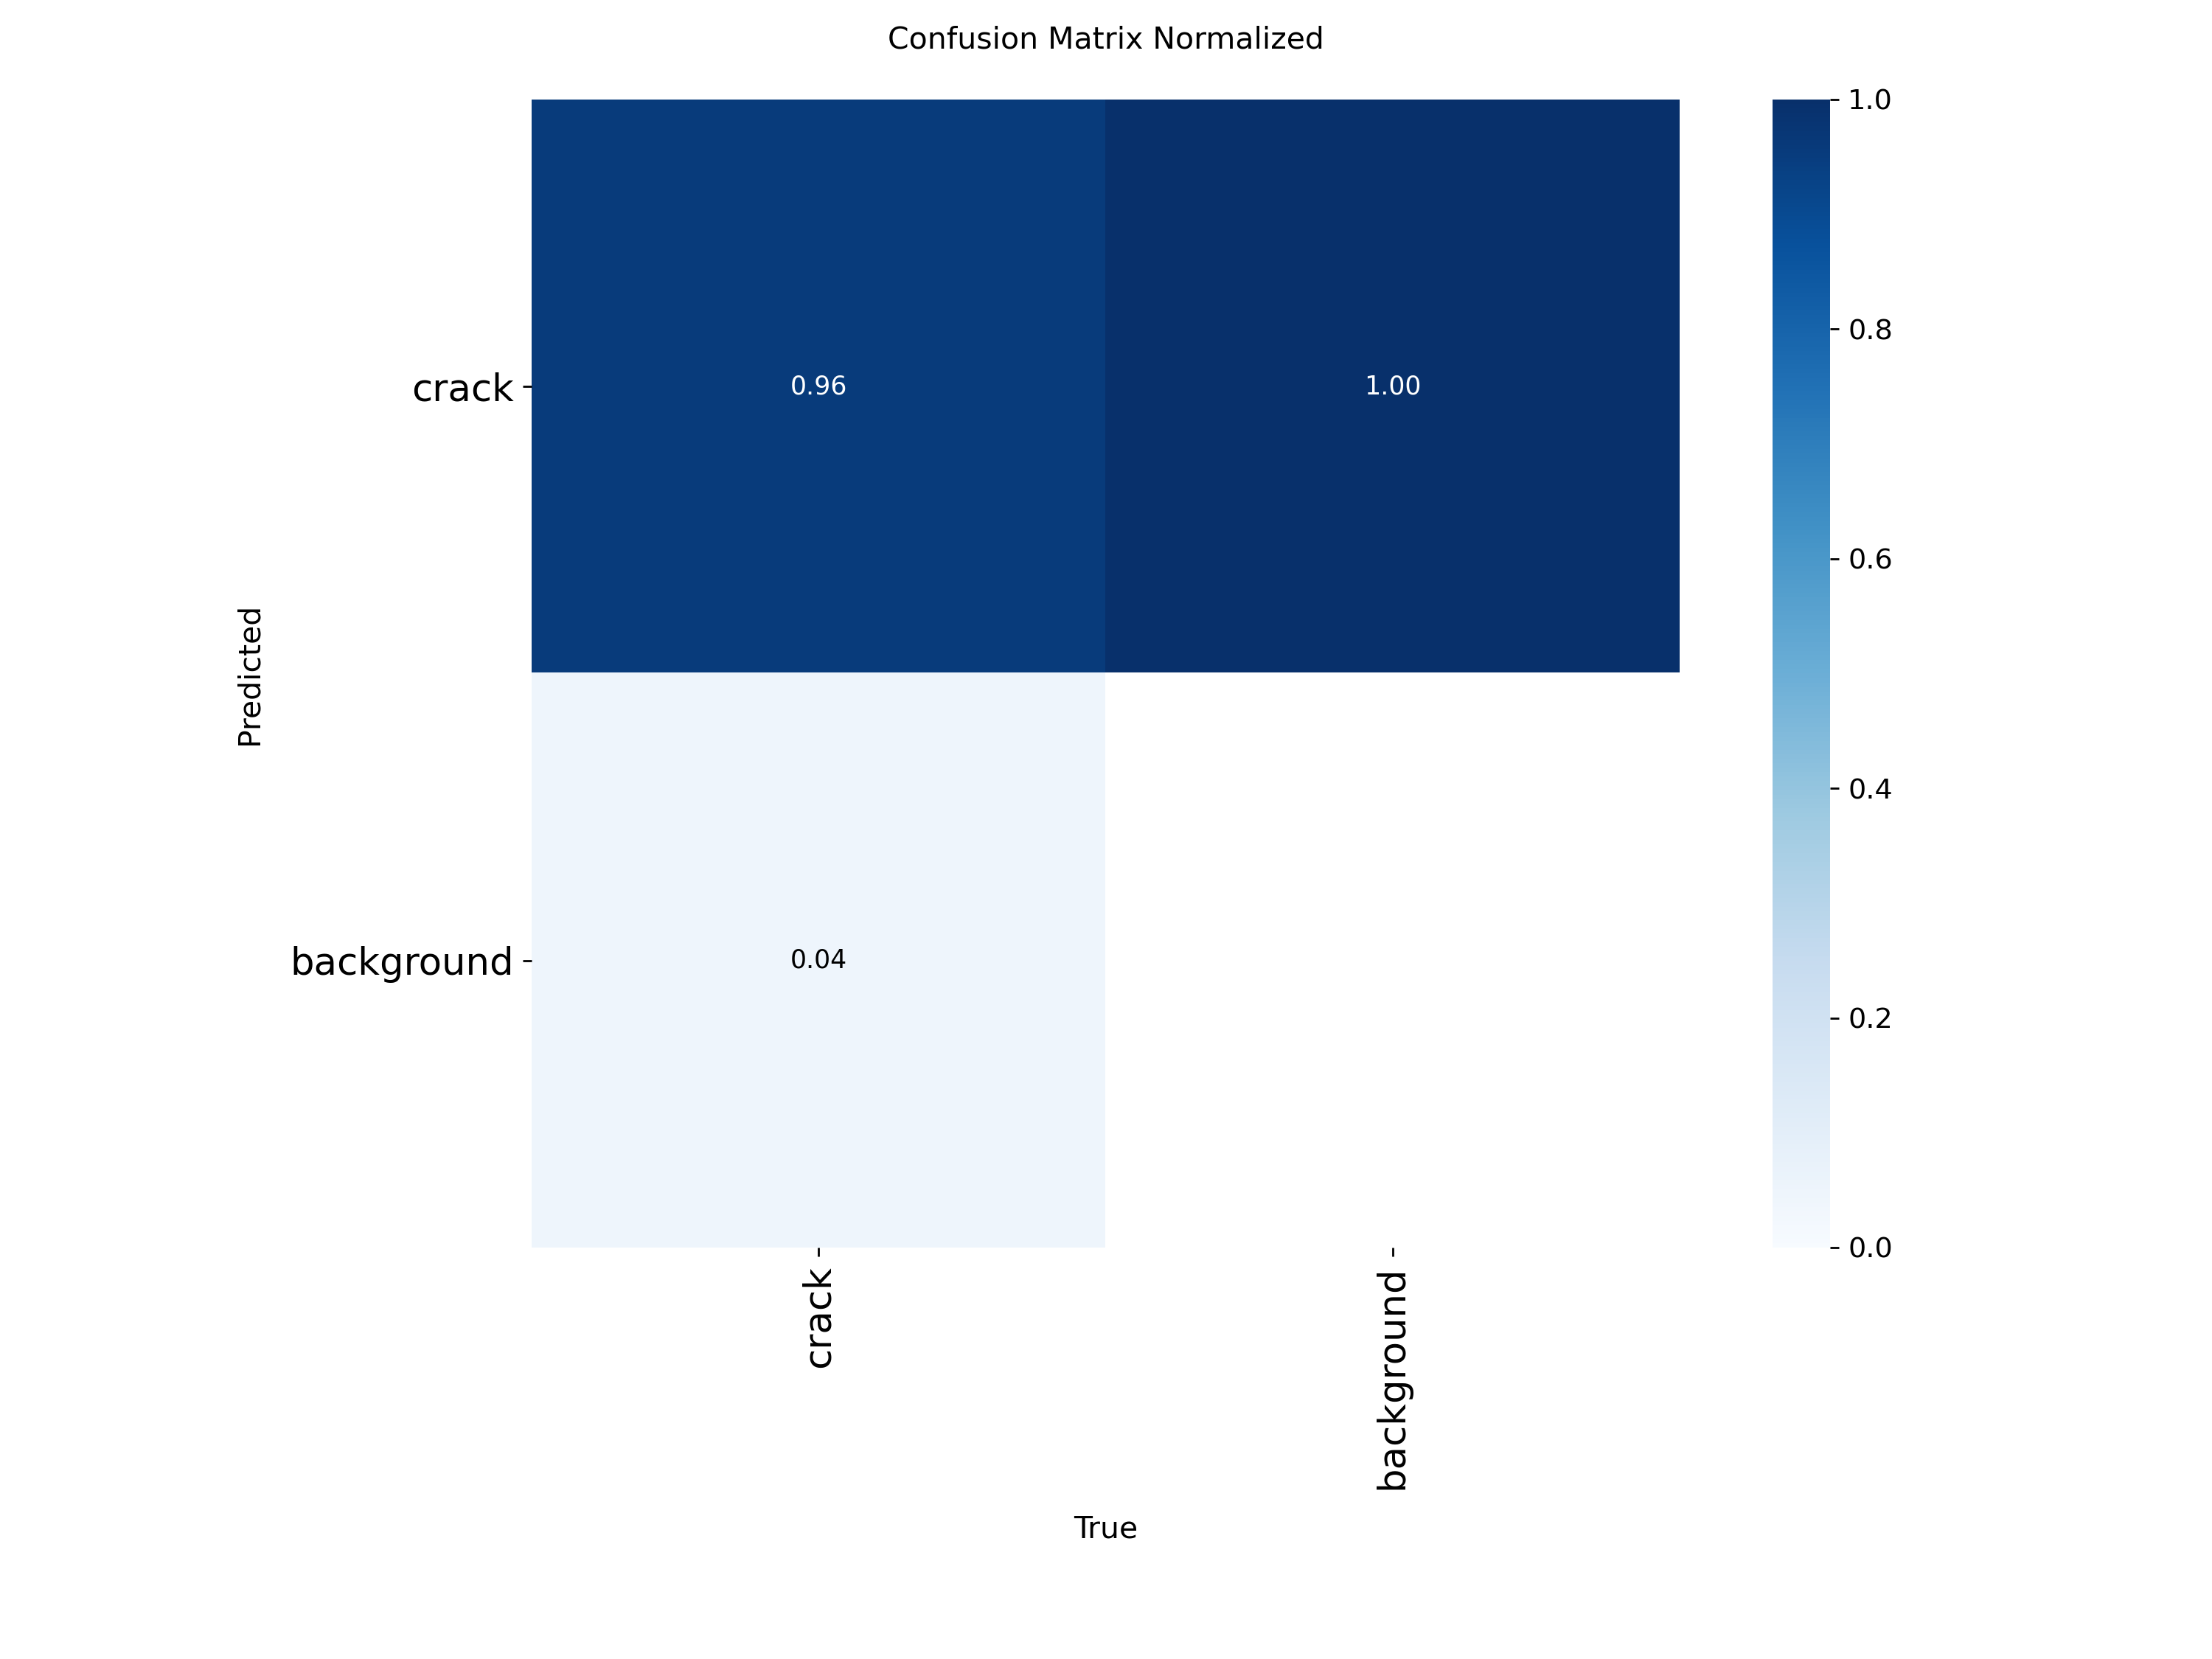

In [21]:
# Find and display evaluation plots
EVALUATION_DIR = Path(
    "/content/drive/MyDrive/CrackVision/evaluation-results"
)

PLOT_DIR = EVALUATION_DIR / "validation-evaluation"

print("Looking for plots in:", PLOT_DIR)

if not PLOT_DIR.exists():
    print("Evaluation folder not found. Check the saved evaluation path.")
else:
    plot_files = sorted(PLOT_DIR.rglob("*.png"))

    if not plot_files:
        print("No PNG plots found in this folder.")
    else:
        for plot_path in plot_files:
            print(f"\n{plot_path.name}")
            display(Image(filename=str(plot_path)))

In [23]:
# Generate and save prediction examples
PREDICTION_DIR = (
    Path("/content/drive/MyDrive/CrackVision")
    / "evaluation-results"
    / "prediction-examples"
)
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

for image_path in sample_paths:
    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        save=False,
        verbose=False
    )[0]

    # Ultralytics draws predicted masks and labels on the image.
    annotated_bgr = result.plot()
    output_path = PREDICTION_DIR / f"{image_path.stem}_prediction.jpg"

    if not cv2.imwrite(str(output_path), annotated_bgr):
        raise IOError(f"Could not save image: {output_path}")

    print("Saved:", output_path.name)

print(f"\nPrediction examples saved to:\n{PREDICTION_DIR}")

Saved: 3421.rf.764d0a36337d51c5e7d7964e1027eb67_prediction.jpg
Saved: 1923.rf.b8291b9800a23b33cb233fcf8a792f9b_prediction.jpg
Saved: 1631.rf.e30824b70361db2a9e2eb7863269ce86_prediction.jpg
Saved: 3828.rf.a46f469000eec6b39a5965bf49a5f56e_prediction.jpg

Prediction examples saved to:
/content/drive/MyDrive/CrackVision/evaluation-results/prediction-examples


In [24]:
# Verify evaluation Artifacts
DRIVE_ROOT = Path("/content/drive/MyDrive/CrackVision")

required_artifacts = {
    "Trained model": DRIVE_ROOT / "models" / "crackvision-yolo11n-seg-best.pt",
    "Validation summary": DRIVE_ROOT / "evaluation-results" / "validation-summary.csv",
    "Prediction examples": (
        DRIVE_ROOT / "evaluation-results" / "prediction-examples"
    ),
    "Validation evaluation folder": (
        DRIVE_ROOT / "evaluation-results" / "validation-evaluation"
    ),
}

print("CrackVision evaluation artifact audit")
print("=" * 45)

all_ok = True

for name, path in required_artifacts.items():
    exists = path.exists()

    if path.is_dir() and name == "Prediction examples":
        count = len(list(path.glob("*"))) if exists else 0
        print(f"{name}: {'OK' if count > 0 else 'MISSING'} ({count} files)")
        all_ok &= count > 0
    else:
        print(f"{name}: {'OK' if exists else 'MISSING'}")
        all_ok &= exists

print("=" * 45)
print("Overall:", "PASS" if all_ok else "CHECK MISSING ITEMS")

CrackVision evaluation artifact audit
Trained model: OK
Validation summary: OK
Prediction examples: OK (4 files)
Validation evaluation folder: OK
Overall: PASS
